# Background-dependence violins and delta bars

General plotting functions for how a focal mutation's effect varies across genetic backgrounds. `plot_graph` draws affinity distributions for each combination of a panel of sites, optionally split by a focal site. `plot_delta` draws the mean change in affinity on acquiring a focal mutation across matched backgrounds, with paired and unpaired t-tests and Benjamini-Hochberg correction. `paired_vi_gen` and `none_all` are layout variants of the
same comparison.

### **Housekeeping & Data Load**

In [ ]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import bisect
import math
import itertools
import warnings
from matplotlib.gridspec import GridSpec
from matplotlib.collections import PolyCollection
from statsmodels.stats.multitest import multipletests
from matplotlib.cbook import index_of
from matplotlib.colors import to_rgb
import colorsys
import matplotlib.patches as patches

warnings.filterwarnings('ignore')

In [ ]:
### color scheme
global_my_colors = ['#8EB4FB','#002792','#386A4F','#CFB454','#B96040','#D48DA6','#6B5894','#741345']
global_my_colors_none_first = ['#6B5894','#8EB4FB','#002792','#386A4F','#CFB454','#B96040','#D48DA6','#741345']

###### Geneerate Label Assignment And Conversion Methods based on the Meta_Df
IMGT_column = 'imgt_position'
Kabat_column = 'kabat_position'
sites_column = 'site'
germline_col = 'germline_aa'
mature_col = 'mature_aa'

### Generates mapping for just the position number
def position_only_convert_label(meta_in,sites_col = sites_column,position_col = IMGT_column):
  mapping = {    }
  for row, site in enumerate(meta_in[sites_col].values):
    mapping[f'{site}'] = f'{meta_in.loc[row,f'{position_col}']}'
  return mapping

### Generates mapping for G#M notation (germline identity)+(Position #)+(mature identity)
def mutation_convert_label(meta_in,sites_col = sites_column,position_col = Kabat_column,g_col = germline_col,m_col = mature_col):
  mapping = {}
  for row, site in enumerate(meta_in[sites_col].values):
    mapping[f'{site}'] = f'{meta_in.loc[row,f'{g_col}']}{meta_in.loc[row,f'{position_col}']}{meta_in.loc[row,f'{m_col}']}'
  return mapping

In [ ]:
data_dir = "../data"
fig_dir = "../figures"
table_dir = "../tables"
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)
png_dpi = 300

plt.rcParams["svg.fonttype"] = "path"   # illustrator drops live text, see the project export note
plt.rcParams["pdf.fonttype"] = 42

bnAb_list = ['1NC9','CH235.12','N49P7','NIH45-46','VRC-PG20','VRC01','VRC07','VRC13','VRC16']

# display name to file stem; the hyphens and the dot do not appear in any filename
name_to_stem = {'1NC9':'1NC9','CH235.12':'CH235_12','N49P7':'N49P7','NIH45-46':'NIH4546',
                'VRC-PG20':'VRCPG20','VRC01':'VRC01','VRC07':'VRC07','VRC13':'VRC13',
                'VRC16':'VRC16'}

rep_avg_cols = ['id','vh_aa'] + [f'site_{i}' for i in range(10)] + ['antigen']


def save_figure(stem):
    """Write the current figure to png, pdf and svg, then check the svg has no live text."""
    name = re.sub(r"[^A-Za-z0-9._-]+", "_", stem).strip("_")
    path = f"{fig_dir}/{name}"
    plt.savefig(f"{path}.png", dpi=png_dpi, bbox_inches="tight")
    plt.savefig(f"{path}.pdf", bbox_inches="tight")
    plt.savefig(f"{path}.svg", bbox_inches="tight")
    assert open(f"{path}.svg").read().count("<text") == 0, "live text in svg, check svg.fonttype"


kds_dict = {}; kds_dict_rep_avg = {}; meta_dict = {}
CH_all_dict = {}; SF_all_dict = {}; CH_params_dict = {}; SF_params_dict = {}
for name in bnAb_list:
    stem = name_to_stem[name]
    kds = pd.read_csv(f"{data_dir}/{stem}_kds.csv")
    kds_dict[name] = kds
    kds_dict_rep_avg[name] = kds.groupby(by=rep_avg_cols).agg({'nlog10_Kd':'mean'}).reset_index()
    meta_dict[name] = pd.read_csv(f"{data_dir}/{stem}_meta.csv")
    CH_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_all.csv")
    SF_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_all.csv")
    CH_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_params.csv")
    SF_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_params.csv")

In [ ]:
CH_params_dict.keys()

dict_keys(['1NC9', 'CH235.12', 'N49P7', 'NIH45-46', 'VRC-PG20', 'VRC01', 'VRC07', 'VRC13', 'VRC16'])

### **Common Functions Code**

In [ ]:
def token_tobit(bnab:str, # 'bnab name'
                antigen: str, # 'CH505TF' or 'SF162' depending on which antigen you want
                tobit_col:str
                ):
  '''''
  Creates a Dataframe with the Gtype +TOBIT Kd

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want

  '''''
  if antigen == 'CH505TF':
    df_all = CH_all_dict[bnab].copy()
  if antigen == 'SF162':
    df_all = SF_all_dict[bnab].copy()
  # kds_in = kds_dict_rep_avg[bnab]
  def formatting(df_in):
    df_in['genotype_tokens'] = df_in[['site_0','site_1','site_2','site_3','site_4','site_5','site_6','site_7','site_8','site_9']].agg(''.join, axis=1)
    df_in['n_somatic'] = ((df_in['site_0'] == 'M').astype(int) + (df_in['site_1'] == 'M').astype(int) + (df_in['site_2'] == 'M').astype(int) +
                                (df_in['site_3'] == 'M').astype(int) + (df_in['site_4'] == 'M').astype(int) + (df_in['site_5'] == 'M').astype(int) +
                                (df_in['site_6'] == 'M').astype(int) + (df_in['site_7'] == 'M').astype(int) + (df_in['site_8'] == 'M').astype(int) +
                                (df_in['site_9'] == 'M').astype(int) )


    if tobit_col == 'censor':
      mapping = {'predicted_kd_full': 'nlog10_Kd','predicted_kd_uncensored': 'Uncensored_Kd'}
    elif tobit_col == 'uncensor':
      mapping = {'predicted_kd_full': 'Censored_Kd','predicted_kd_uncensored': 'nlog10_Kd'}
    else:
      return print('print_error')
    return df_in.rename(columns = mapping)

  df_all = formatting(df_all).copy()

  return df_all


def token_kds(bnab: str,antigen: str,
              tobit_col: str = None,
              CH_Kdthreshold:list = None,
              SF_Kdthreshold: list = None):
  '''''
  Creates a Dataframe with the Gtype +RAW Kd

  bnab = 'bnab name'

  antigen = 'CH505TF' or 'SF162' depending on which antigen you want

  '''''
  df = kds_dict_rep_avg[bnab]
  if CH_Kdthreshold is not None or SF_Kdthreshold is not None:
    df_wide = df.groupby(['id', 'antigen'])['nlog10_Kd'].mean().unstack().reset_index()
    df_wide = df_wide[(df_wide['CH505TF'] >= CH_Kdthreshold[0]) & (df_wide['CH505TF'] <= CH_Kdthreshold[1])].copy()
    df_wide = df_wide[(df_wide['SF162'] >= CH_Kdthreshold[0]) & (df_wide['SF162'] <= CH_Kdthreshold[1])].copy()
    ids_to_save = df_wide['id']
    df = df[df['id'].isin(ids_to_save)]


  if antigen == 'CH505TF':
    df = df[df['antigen'] == antigen].copy()
  elif antigen == 'SF162':
    df = df[df['antigen'] == antigen].copy()

  df['genotype_tokens'] = df[['site_0','site_1','site_2','site_3','site_4','site_5','site_6','site_7','site_8','site_9']].agg(''.join, axis=1)
  df['n_somatic'] = ((df['site_0'] == 'M').astype(int) + (df['site_1'] == 'M').astype(int) + (df['site_2'] == 'M').astype(int) +
                               (df['site_3'] == 'M').astype(int) + (df['site_4'] == 'M').astype(int) + (df['site_5'] == 'M').astype(int) +
                               (df['site_6'] == 'M').astype(int) + (df['site_7'] == 'M').astype(int) + (df['site_8'] == 'M').astype(int) +
                               (df['site_9'] == 'M').astype(int) )




  return df


def token_tobit_updated(bnab:str, # 'bnab name'
                antigen: str, # 'CH505TF' or 'SF162' depending on which antigen you want
                tobit_col:str
                ):
  '''''
  Creates a Dataframe with the Gtype +TOBIT Kd. This updated token_tobit replaces measured Kd values with the tobit estimates.
  It DOES NOT use the full, complete combinatorial set of genotypes like the way the first token_tobit function presents genotypes
  that were never measured.

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want

  '''''
  if antigen == 'CH505TF':
    df_all = CH_all_dict[bnab].copy()
    df_raw = token_kds(bnab,'CH505TF').copy()
  if antigen == 'SF162':
    df_all = SF_all_dict[bnab].copy()
    df_raw = token_kds(bnab,'SF162').copy()
  # kds_in = kds_dict_rep_avg[bnab]

  if tobit_col == 'censor':
    mapping = {'predicted_kd_full': 'nlog10_Kd','predicted_kd_uncensored': 'Uncensored_Kd'}
  elif tobit_col == 'uncensor':
    mapping = {'predicted_kd_full': 'Censored_Kd','predicted_kd_uncensored': 'nlog10_Kd'}
  else:
    return print('print_error')

  df_all['genotype_tokens'] = df_all[['site_0','site_1','site_2','site_3','site_4','site_5','site_6','site_7','site_8','site_9']].agg(''.join, axis=1)
  df_all['n_somatic'] = ((df_all['site_0'] == 'M').astype(int) + (df_all['site_1'] == 'M').astype(int) + (df_all['site_2'] == 'M').astype(int) +
                              (df_all['site_3'] == 'M').astype(int) + (df_all['site_4'] == 'M').astype(int) + (df_all['site_5'] == 'M').astype(int) +
                              (df_all['site_6'] == 'M').astype(int) + (df_all['site_7'] == 'M').astype(int) + (df_all['site_8'] == 'M').astype(int) +
                              (df_all['site_9'] == 'M').astype(int) )

  df_all = df_all.rename(columns = mapping)

  df_raw['nlog10_Kd'] = df_raw['genotype_tokens'].map(df_all.set_index('genotype_tokens')['nlog10_Kd'])


  return df_raw

In [ ]:
def adjust_lightness(color, l_f, s_f):
    h, l, s = colorsys.rgb_to_hls(*to_rgb(color))
    l = max(0, min(1, l * l_f))
    s = max(0, min(1, s * s_f))
    return colorsys.hls_to_rgb(h, l, s)

def all_subset_columns(row_labels):
    """Every subset of the sites, ordered by size: none, singles, pairs, ..., all."""
    cols = []
    for k in range(len(row_labels) + 1):
        for combo in itertools.combinations(row_labels, k):
            cols.append(list(combo))
    return cols


def genotype_grid(ax, row_labels, columns, tick_pos, counts=None,
                  on_color="#222222", off_color="#E2E2E2", dot_size=26,
                  label_size=9, count_size=6.5, x_axis_padding_l = -1, x_axis_padding_r = 0):
    """Filled dot = site mutated, light dot = germline. Row labels on y, optional n=.. below.
    ax          axes to draw on (usually a short axes below the main plot, shared x)
    row_labels  site names top to bottom, e.g. ["N52D","S53R","G54R","T57P"]
    columns     one entry per x position: the sites mutated in that genotype (empty = germline)
    counts      optional list of ints (len == columns), shown as n=.. beneath
    """
    n_rows = len(row_labels)
    row_y = {lab: n_rows - 1 - i for i, lab in enumerate(row_labels)}  # first label on top
    for x, present in zip(tick_pos, columns):
        if type(present) != list:
          present = present.split(',')

        if 'All' in present:

          present = row_labels

        present = set(present)
        for lab in row_labels:
            ax.scatter(x, row_y[lab], s=dot_size, zorder=2,
                       color=on_color if lab in present else off_color)
    if counts is not None:
        for x, n in enumerate(counts):
            ax.text(x, -1.0, f"n={n}", ha="center", va="top", fontsize=count_size, color="#262626")

    ax.set_ylim(-1.9 if counts is not None else -0.6, n_rows - 0.4)
    ax.set_xticks(tick_pos); ax.set_yticks(range(n_rows))
    ax.set_yticklabels(row_labels[::-1], fontsize=label_size)
    ax.set_xlim(x_axis_padding_l,len(tick_pos)-x_axis_padding_r)
    ax.tick_params(axis = 'x', labelsize = 0,length = 0)
    ax.tick_params(axis = 'y', length = 0)
    for spine in ax.spines.values(): spine.set_visible(False)
    return ax

In [ ]:
def combinatorial(panel_s: list):
  '''''
  Creates a combinatorially complete list of site combinations

  panel_s = list of sites in panel eg. [1,2,3,5]

  Order of sites is none - single - double - ... - all

  '''''
  combinatorial_l = []
  for r in range(2, len(panel_s)+1):
    combinatorial_l.extend((itertools.combinations(panel_s, r)))
  combinatorial_l = [[]] + [ list(x) for x in [[s] for s in panel_s] + list(combinatorial_l)]
  return combinatorial_l


def combinatorial_new(panel_s: list):
  '''''
  Creates a combinatorially complete list of site combinations

  panel_s = list of sites in panel eg. [1,2,3,5]

  Order of sites is single - double - ... - none - all

  '''''
  combinatorial_l = []
  for r in range(2, len(panel_s)+1):
    combinatorial_l.extend((itertools.combinations(panel_s, r)))
  combinatorial_l = [ list(x) for x in [[s] for s in panel_s] ] + list(combinatorial_l)[:-1] +[[]] + [list(combinatorial_l[-1])]
  return combinatorial_l

print(combinatorial([2,3,4]))
combinatorial_new([2,3,4])

[[], [2], [3], [4], [2, 3], [2, 4], [3, 4], [2, 3, 4]]


[[2], [3], [4], (2, 3), (2, 4), (3, 4), [], [2, 3, 4]]

### **Unpaired Violins (Split and Unsplit)**

In [ ]:
def data_gen_new(bnab : str,
             df_function,
             background: list, # even if you have single background, [] format required
             background_identity: str,
             panels: list,
             panels_identity: str,
             auxiliary_site: list = None,
             auxiliary_identity: str = None,
             tobit_col: str = None,
             CH_Kdthreshold: list = None,
             SF_Kdthreshold: list = None):


  '''''
  ---- Parameters ----
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)

  backgroud = the site you kept as focal mutation eg. [5] for position 5
  background_identity = 'M' or 'G'

  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'

  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  antigen_Kdthreshold: list = tuple of [min,max] for each antigen Kd. Defaults to the whole data.

  ---- Outputs ----
  CH_result: dictionary with keys representing panel combinations and the value being the array of Kd values for that combination on CH505TF

  SF_result: dictionary with keys representing panel combinations and the value being the array of Kd values for that combination on SF162

  combinatorial_l

  '''''

  # Load Data
  meta_in = meta_dict[bnab]
  Kabat_mapping = mutation_convert_label(meta_in,sites_column,Kabat_column)

  if df_function == token_tobit:
    df_CH = token_tobit(bnab,'CH505TF',tobit_col)
    df_SF = token_tobit(bnab,'SF162',tobit_col)
  elif df_function == token_kds:
    df_CH = token_kds(bnab,'CH505TF',CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
    df_SF = token_kds(bnab,'SF162',CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  elif df_function == token_tobit_updated:
    df_CH = token_tobit_updated(bnab,'CH505TF',tobit_col)
    df_SF = token_tobit_updated(bnab,'SF162',tobit_col)

  ### Load combinatorial Combinations
  combinatorial_l = combinatorial(panels)
  combinatorial_l = combinatorial_l[1:-1] + [[]] + [combinatorial_l[-1]]

  ### Set up the dataset with the correct background identity
  for site_num in background:
    df_CH = df_CH[df_CH[f'site_{site_num}'] == background_identity].copy()
    df_SF = df_SF[df_SF[f'site_{site_num}'] == background_identity].copy()
  ### Establish appropriate extra conditions when appropriate:
  if auxiliary_site is not None:
    for aux_s in auxiliary_site:
      df_CH = df_CH[df_CH[f'site_{aux_s}'] == auxiliary_identity].copy()
      df_SF = df_SF[df_SF[f'site_{aux_s}'] == auxiliary_identity].copy()

  ### Creae Output Dictionary save key as the site combination and value as the array of Kd
  CH_result = {}; SF_result = {}


  ### Create Array for each group in the combinatorial list
  for idx, group in enumerate(combinatorial_l):
    CHdf_temp = df_CH.copy()
    SFdf_temp = df_SF.copy()
    key_label = ','.join([Kabat_mapping[f'site_{s}'] for s in group])
    ## for each site within each term in the combinatorial_l
    for ps in group:
      CHdf_temp = CHdf_temp[CHdf_temp[f'site_{ps}'] == panels_identity].copy()
      SFdf_temp = SFdf_temp[SFdf_temp[f'site_{ps}'] == panels_identity].copy()

    #### Hold remaining panel sites as opposite of designated panel identity
    identity_l = ['M','G']
    exclusion_id = [s for s in identity_l if s != panels_identity][0]
    exclusions = [gs for gs in panels if gs not in group]
    for ex_s in exclusions:
      CHdf_temp = CHdf_temp[CHdf_temp[f'site_{ex_s}'] == exclusion_id].copy()
      SFdf_temp = SFdf_temp[SFdf_temp[f'site_{ex_s}'] == exclusion_id].copy()

    ### Add dictionary entries
    if len(group) == 0:
      CH_result['None'] = CHdf_temp; SF_result['None'] = SFdf_temp
    elif len(group) == len(panels):
      CH_result['All'] = CHdf_temp; SF_result['All'] = SFdf_temp

    else:
      CH_result[key_label] = CHdf_temp; SF_result[key_label] = SFdf_temp

  #### Tobit and Bg Averaged Effect
  ## If background site is purely additive (by model)?
  CHparam = 0; SFparam = 0
  CHpdict = CH_params_dict[bnab]; SFpdict = SF_params_dict[bnab]
  for bs in background:
    row_idxCH = CHpdict.index[CHpdict['term'] == f'site_{bs}'][0]
    row_idxSF = SFpdict.index[SFpdict['term'] == f'site_{bs}'][0]

    CHparam += CHpdict.loc[row_idxCH,'coefficient']
    SFparam += SFpdict.loc[row_idxSF,'coefficient']

  ## Is this change more or less than change incurred by difference in background across raw data? (bg avg)
  CH_df = token_kds(bnab,'CH505TF').reset_index()
  SF_df = token_kds(bnab, 'SF162').reset_index()

  CH_dfM = CH_df.copy() ; SF_dfM = SF_df.copy()
  for bs in background:
    CH_dfM = CH_dfM[CH_dfM[f'site_{bs}'] == 'M'].copy()
    SF_dfM = SF_dfM[SF_dfM[f'site_{bs}'] == 'M'].copy()
  CH_dfM = CH_df.reset_index() ; SF_dfM = SF_df.reset_index()

  def bg_avg_delta(df,raw):
    reverted_Kd_l = []
    for i in range(len(df)):
      revertant = df.loc[i,'genotype_tokens'] ## baseline genotype
      for bs in background: ## modify to x-th mutant with the mutations
        revertant = revertant[:bs] + 'G' + revertant[bs+1:]
      if revertant in list(raw['genotype_tokens']):
        revertant_row = raw.index[raw['genotype_tokens'] == revertant][0]
        existing_revertantKd = raw.loc[revertant_row,'nlog10_Kd']
        delta = df.loc[i,'nlog10_Kd'] - existing_revertantKd
        reverted_Kd_l.append(delta)

    return np.mean(reverted_Kd_l), np.std(reverted_Kd_l)

  CH_bg_avg_delta = bg_avg_delta(CH_dfM,CH_df)
  SF_bg_avg_delta = bg_avg_delta(SF_dfM,SF_df)


  return CH_result, SF_result, CHparam, SFparam, CH_bg_avg_delta, SF_bg_avg_delta, combinatorial_l

In [ ]:
def data_gen(bnab : str,
             df_function,
             background: list, # even if you have single background, [] format required.
             background_identity: str,
             panels: list,
             panels_identity: str,
             combinatorial_function = combinatorial,
             auxiliary_site: list = None,
             auxiliary_identity: str = None,
             tobit_col: str = None,
             CH_Kdthreshold: list = None,
             SF_Kdthreshold: list = None):


  '''''
  ---- Parameters ----
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)

  backgroud = the site you kept as focal mutation eg. [5] for position 5
  background_identity = 'M' or 'G'

  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'

  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  antigen_Kdthreshold: list = tuple of [min,max] for each antigen Kd. Defaults to the whole data.

  ---- Outputs ----
  CH_result: dictionary with keys representing panel combinations and the value being the array of Kd values for that combination on CH505TF

  SF_result: dictionary with keys representing panel combinations and the value being the array of Kd values for that combination on SF162

  combinatorial_l

  '''''

  # Load Data
  meta_in = meta_dict[bnab]
  Kabat_mapping = mutation_convert_label(meta_in,sites_column,Kabat_column)

  if df_function == token_tobit:
    df_CH = token_tobit(bnab,'CH505TF',tobit_col)
    df_SF = token_tobit(bnab,'SF162',tobit_col)
  elif df_function == token_kds:
    df_CH = token_kds(bnab,'CH505TF',CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
    df_SF = token_kds(bnab,'SF162',CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  elif df_function == token_tobit_updated:
    df_CH = token_tobit_updated(bnab,'CH505TF',tobit_col)
    df_SF = token_tobit_updated(bnab,'SF162',tobit_col)


  ### Load combinatorial Combinations
  combinatorial_l = combinatorial_function(panels)
  if combinatorial_function is combinatorial:
    combinatorial_l = combinatorial_l[1:-1] + [[]] + [combinatorial_l[-1]]
  elif combinatorial_function is combinatorial_new:
    combinatorial_l = combinatorial_l  # already in single→pair→...→None→All order


  ### Set up the dataset with the correct background identity
  for site_num in background:
    df_CH = df_CH[df_CH[f'site_{site_num}'] == background_identity].copy()
    df_SF = df_SF[df_SF[f'site_{site_num}'] == background_identity].copy()
  ### Establish appropriate extra conditions when appropriate:
  if auxiliary_site is not None:
    for aux_s in auxiliary_site:
      df_CH = df_CH[df_CH[f'site_{aux_s}'] == auxiliary_identity].copy()
      df_SF = df_SF[df_SF[f'site_{aux_s}'] == auxiliary_identity].copy()

  ### Creae Output Dictionary save key as the site combination and value as the array of Kd
  CH_result = {}; SF_result = {}


  ### Create Array for each group in the combinatorial list
  for idx, group in enumerate(combinatorial_l):
    CHdf_temp = df_CH.copy()
    SFdf_temp = df_SF.copy()
    key_label = ','.join([Kabat_mapping[f'site_{s}'] for s in group])
    ## for each site within each term in the combinatorial_l
    for ps in group:
      CHdf_temp = CHdf_temp[CHdf_temp[f'site_{ps}'] == panels_identity].copy()
      SFdf_temp = SFdf_temp[SFdf_temp[f'site_{ps}'] == panels_identity].copy()

    #### Hold remaining panel sites as opposite of designated panel identity
    identity_l = ['M','G']
    exclusion_id = [s for s in identity_l if s != panels_identity][0]
    exclusions = [gs for gs in panels if gs not in group]
    for ex_s in exclusions:
      CHdf_temp = CHdf_temp[CHdf_temp[f'site_{ex_s}'] == exclusion_id].copy()
      SFdf_temp = SFdf_temp[SFdf_temp[f'site_{ex_s}'] == exclusion_id].copy()

    ### Add dictionary entries
    if len(group) == 0:
      CH_result['None'] = CHdf_temp['nlog10_Kd'].values ; SF_result['None'] = SFdf_temp['nlog10_Kd'].values
    elif len(group) == len(panels):
      CH_result['All'] = CHdf_temp['nlog10_Kd'].values ; SF_result['All'] = SFdf_temp['nlog10_Kd'].values

    else:
      CH_result[key_label] = CHdf_temp['nlog10_Kd'].values ; SF_result[key_label] = SFdf_temp['nlog10_Kd'].values


  return CH_result, SF_result, combinatorial_l

In [ ]:
def plot_graph(BnAb: str,
               df_function,
               background_list: list = [],
               panel: list = [],
               panel_identity: str = 'M',
               combinatorial_function = combinatorial,
               auxiliary_site: list = None,
               auxiliary_identity: str = None,
               tobit_col: str = None,
               CH_Kdthreshold: list = None,
               SF_Kdthreshold: list = None,
               color_l:list  = global_my_colors,
               plot_vi: bool = True,
               plot_split: bool = True,
               save_fig: bool = False,
               save_fig_title: str = '',
               save_fig_mode: str = '.pdf'):

  '''''
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)

  backgroud = the site you kept as focal mutation eg. [5] for position 5

  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'. Defaults to 'M' But change to 'G' if you wish the x-axis genotypes to hold the set of sites germline

  combinatorial_function = combinatorial or combinatorial_new changes the order of violins on the x-axis

  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  Kdthreshold = list of [min,max] for each antigen Kd. Defaults to the whole data.
  global_my_colors = default color scheme
  plot_vi = a boolean for strip plot vs. violin plot. Pass true by default for violin
  plot_split = a boolean for split violins. Pass True by default for split violins

  save_fig = True or False. Assign True to save figure
  save_fig_title = If save_fig is True, also pass this argument with desired title header. Title Provides basic infomration automatically, but
                    use this argument to add additional description. Argument defaults to an empty string if not passed.

  save_fig_mode = specify file format .pdf or .png
  '''''

  meta_in = meta_dict[BnAb]
  Kabat_mapping = mutation_convert_label(meta_in,sites_column,Kabat_column)


  ### Call Data
  bgG_CH, bgG_SF,combinatorial_l = data_gen(BnAb,df_function,background_list, 'G', panel,panel_identity,combinatorial_function,auxiliary_site,
                                            auxiliary_identity,tobit_col,CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  bgM_CH, bgM_SF,_ =               data_gen(BnAb,df_function,background_list, 'M', panel,panel_identity,combinatorial_function, auxiliary_site, auxiliary_identity,
                                            tobit_col,CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)

  ## Compile in an array for data processing
  output_dict = np.array([bgG_CH,bgG_SF,bgM_CH,bgM_SF],dtype = 'object')
  ## Create grid of x label with N
  labels_arr = np.zeros(2,dtype = 'object')
  for i in range(2):
    dic_g = output_dict[i]
    dic_m = output_dict[i+2]
    site_label = [txt.replace(',','\n') for txt in dic_g.keys()] # site_label provides Kabat Position for the mutations in each group
    if plot_split:
      # for splits, record both g and m
      labels_arr[i] = [f'{len(g_group)}\n{len(m_group)}' for g_group, m_group in zip(dic_g.values(),dic_m.values())]
    else:
      # if unsplit, the counts are the same and record only one
      labels_arr[i] = [f'{len(g_group)}' for g_group in dic_g.values()]
  print(labels_arr)
  # extract panel sites
  full_term = bgG_CH.keys()
  single_term = [term for term in list(bgG_CH.keys()) if ',' not in term]
  single_term = [term for term in single_term if term not in ['None', 'All']]
  # call figure
  fig, axes =   plt.subplots(2,2, figsize = (24, 8), height_ratios= [1.5,.5])
  ax_flat = axes.flatten()

  max_val = 0
  for dic in output_dict:
    dic_max_l = np.zeros(len(dic.keys()))
    for i,val in enumerate(dic.values()):
      # Handle potential empty arrays or all-NaN arrays for np.max
      if len(val) > 0 and not np.all(np.isnan(val)):
        dic_max_l[i] = np.nanmax(val)
      else:
        dic_max_l[i] = np.nan # Use NaN if no valid max
    dic_max = np.nanmax(dic_max_l) if not np.all(np.isnan(dic_max_l)) else 0 # Handle case where all max values are NaN
    if max_val < dic_max:
      max_val = dic_max

  for i in range(2):
    ax_flat[i].set_axisbelow(True)
    ax_flat[i].set_ylim(5.6, top = max_val+.1)
    ax_flat[i].set_xlim(0,len(combinatorial_l)+1)

  for plot in range(2):
      left_G_dict = output_dict[plot] ## Call dictionary one by one
      right_M_dict = output_dict[plot+2]
      # convert to dataframe to plot more easily
      # uneven lengths accomodated with np.nan positioning
      left_G_df = pd.DataFrame({key: pd.Series(value) for key, value in left_G_dict.items()})
      right_M_df = pd.DataFrame({key: pd.Series(value) for key, value in right_M_dict.items()})
      left_G_df = left_G_df.melt(var_name = 'sites', value_name = 'Kd')
      left_G_df = left_G_df.assign(identity = 'germline')

      right_M_df = right_M_df.melt(var_name = 'sites', value_name = 'Kd')
      right_M_df = right_M_df.assign(identity = 'mature')

      plotted_df = pd.concat([left_G_df, right_M_df]).reset_index(drop = 'index')

      palette = sns.color_palette("Paired")



      if plot_vi:
        if plot_split == False:
          sns.violinplot(ax = ax_flat[plot],data = plotted_df,x = 'sites', y = 'Kd', palette = color_l,
                        inner = None,density_norm='count',cut = 0,
                        linewidth = 1)

        if plot_split:
          sns.violinplot(ax = ax_flat[plot],data = plotted_df,x = 'sites', y = 'Kd', hue = 'identity', split = True,
                        inner = None,density_norm='count',cut = 0,palette = color_l,
                        linewidth = 1)


          unique_sites_order = list(plotted_df['sites'].unique())  # must match x-axis draw order
          base_colors = sns.color_palette('tab10', len(unique_sites_order))

          violin_patches = [c for c in ax_flat[plot].collections if c.__class__.__name__ == 'PolyCollection']
          violin_bodies = [c for c in ax_flat[plot].collections if 'Poly' in type(c).__name__]
          if not violin_bodies:
              violin_bodies = [p for p in ax_flat[plot].patches if 'Path' in type(p).__name__ or 'Polygon' in type(p).__name__]


          for i, site in enumerate(unique_sites_order):
              light_shade = adjust_lightness(base_colors[i], 1.4,1.2)  # germline half
              dark_shade  = adjust_lightness(base_colors[i], .8,1.2)  # mature half
              violin_bodies[i*2].set_facecolor(light_shade)
              violin_bodies[i*2 + 1].set_facecolor(dark_shade)

        # Manual legend since real colors no longer match seaborn's default hue legend
        if ax_flat[plot].legend_ is not None:
          ax_flat[plot].legend_.remove()
      else:
        sns.stripplot(ax = ax_flat[plot],data = plotted_df,x = 'sites',y = 'Kd', hue = 'identity',
                        palette = 'muted',jitter = .3,zorder= 5)

      medians_raw_g = []
      medians_raw_m = []
      unique_sites = list(plotted_df['sites'].unique())
      for combination in unique_sites:
        germline_group_data = plotted_df[(plotted_df['sites'] == combination) & (plotted_df['identity'] == 'germline')].copy()
        mature_group_data = plotted_df[(plotted_df['sites'] == combination) & (plotted_df['identity'] == 'mature')].copy()

        valid_kds_m = mature_group_data['Kd'].dropna()
        valid_kds_g = germline_group_data['Kd'].dropna()
        if not valid_kds_g.empty:
          median_group_g = np.median(valid_kds_g.values)
        else:
          median_group_g = np.nan
        medians_raw_g.append(median_group_g)
        if not valid_kds_m.empty:
          median_group_m = np.median(valid_kds_m.values)
        else:
          median_group_m = np.nan
        medians_raw_m.append(median_group_m)

        medians = np.array([medians_raw_g,medians_raw_m],dtype = 'object')

      # Filter out NaN medians for plotting scatter and errorbar
      x_for_plot_medians = list(range(len(unique_sites))) # X-coordinates correspond to the order of unique sites
      valid_x_for_plot_medians = [x for x, y in zip(x_for_plot_medians, medians_raw_g) if not np.isnan(y)]
      valid_y_for_plot_medians_germline = [y for y in medians_raw_g if not np.isnan(y)]
      valid_y_for_plot_medians_somatic = [y for y in medians_raw_m if not np.isnan(y)]

      if plot_split:
        ax_flat[plot].scatter(x = [coor-.18 for coor in valid_x_for_plot_medians], y = valid_y_for_plot_medians_germline, edgecolor = 'k',linewidths = 1.5, color = 'white', s = 45, zorder = 5, label = 'median')
        ax_flat[plot].scatter(x = [coor+.18 for coor in valid_x_for_plot_medians], y = valid_y_for_plot_medians_somatic,edgecolor = 'k',linewidths = 1.5, color = 'white',marker = 'o', s = 55, zorder = 5)
      elif plot_split == False:
        ax_flat[plot].scatter(x = [coor for coor in valid_x_for_plot_medians], y = valid_y_for_plot_medians_germline, edgecolor = 'k',linewidths = 1.5, color = 'white', s = 45, zorder = 5, label = 'median')



      ax_flat[plot].set(xlim = (-1,len(full_term)), xlabel = ' ', xticks = list(range(len(labels_arr[plot]))))
      # ax_flat[plot].set_xticks(list(range(len(labels_arr[plot]))))
      if plot_vi is False:
        ax_flat[plot].errorbar(x = valid_x_for_plot_medians, y = valid_y_for_plot_medians_germline, linewidth = 3, xerr = .3,fmt = 'o',zorder = 1,capsize = 0,color = 'k')
      ax_flat[plot].set_xticklabels([])

  # plot label grid
  for grid_plot in range(2,4):
    genotype_grid(ax_flat[grid_plot], single_term, full_term,range(len(full_term)),label_size= 12)
    for x, txt in enumerate(labels_arr[grid_plot-2]):
      ax_flat[grid_plot].text(x, -1.0, f"{txt}", ha="center", va="top", fontsize= 12, color="k")

    ax_flat[grid_plot].text(-.5,-1.0, ('germline =\nmature =' if plot_split == True else 'n ='), fontsize = 12, color = 'k',ha = 'right', va = 'top')

  ## Build Labels
  sites = ','.join([Kabat_mapping[f'site_{i}'] for i in background_list])
  panels_label = ','.join([Kabat_mapping[f'site_{i}'] for i in panel])
  if auxiliary_identity == 'G':
    auxiliary_label = '           extra condition: ' + '-'+'-'.join([Kabat_mapping[f'site_{i}'] for i in auxiliary_site])
  elif auxiliary_identity == 'M':
    auxiliary_label = '           extra condition: +'+'+'.join([Kabat_mapping[f'site_{i}'] for i in auxiliary_site])
  elif auxiliary_identity is None:
    auxiliary_label = ' '

  ### build patch label for violin splits
  patch_x, patch_y = 0.02, 0.9      # top-left corner of patch, in axes coords
  patch_width, patch_height = 0.03, 0.05
  patch_pad = 0.02
  background_label = ','.join([Kabat_mapping[f'site_{bs}']for bs in background_list])
  ax = ax_flat[0]
  # only plot on left
  #### only add path delta labels for splits
  if plot_split:

    for idx, label in enumerate([f'–{background_label}', f'+{background_label}']):
      rect = patches.Rectangle(
          (patch_x, (patch_y if idx == 0 else patch_y - patch_height - patch_pad)),             # bottom-left corner
          patch_width, patch_height,
          transform=ax.transAxes,         # use axes-fraction coordinates, not data coordinates
          facecolor= ('lightgray' if idx == 0 else 'dimgray'),
          edgecolor='k',
          linewidth=0.8,
          clip_on=False                   # don't clip if patch sits near the edge
      )
      ax.add_patch(rect)

      # Label to the right of the patch
      if idx == 0:
        text_y = patch_y + patch_height / 2
      elif idx == 1:
        text_y = patch_y - patch_height - patch_pad + patch_height / 2
      ax.text(
          patch_x + patch_width + 0.01,   # small gap to the right of the patch
          text_y,     # vertically centered on the patch
          label,
          transform=ax.transAxes,
          ha='left', va='center',
          fontsize=12
      )
    text_y = patch_y -2 * ( patch_height+ patch_pad) + patch_height / 2
    ax.scatter(x = [patch_x+patch_width/2], y = [text_y], c = 'white', edgecolors = 'k', s = 80, transform=ax.transAxes, linewidths = 2)
    ax.text(patch_x + patch_width + 0.01, text_y, 'median',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')
  else:
    text_y = patch_y + patch_height / 2
    ax.scatter(x = [patch_x+patch_width/2], y = [text_y], c = 'white', edgecolors = 'k', s = 80, transform=ax.transAxes, linewidths = 2)
    ax.text(patch_x + patch_width + 0.01, text_y, 'median',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')


  sites_pos_replacement = sites.replace(",",',')
  # assign labels
  if auxiliary_identity is not None:
    ax_flat[0].set_title(f'CH505TF\nfocal: {sites_pos_replacement}{auxiliary_label}', fontsize = 16)
    ax_flat[0].set_ylabel(r'-log$_{10}K_{D}$', fontsize = 14)
    ax_flat[1].set_title(f'SF162\nfocal: {sites_pos_replacement}{auxiliary_label}', fontsize = 16)
    ax_flat[1].set_ylabel(r'-log$_{10}K_{D}$', fontsize = 14)
  else:
    ax_flat[0].set_title(f'CH505TF', fontsize = 16, weight = 'bold')
    ax_flat[0].set_ylabel(r'-log$_{10}K_{D}$', fontsize = 14)
    ax_flat[1].set_title(f'SF162', fontsize = 16, weight = 'bold')
    ax_flat[1].set_ylabel(r'-log$_{10}K_{D}$', fontsize = 14)

  for i in range(2):
    ax_flat[i].set_yticks(np.arange(6,max_val,0.5))
    ax_flat[i].grid(axis  = 'y')
    num_term  = len(single_term)
    ax_flat[i].axhline(y = 6,linewidth = 1.5,linestyle = ':', color = 'darkgreen',zorder = 0.5)
    ax_flat[i].axvline(x = len(combinatorial_l)-2.5, linewidth = 1.2, color = 'k',linestyle = '--')
    ax_flat[i].axvline(x = num_term-0.5, linewidth = 1, color = 'k',linestyle = '--')
    if len(single_term) >= 4:
      ax_flat[i].axvline(x = math.comb(num_term,2)+num_term-0.5, linewidth = 1, color = 'k',linestyle = '--')
  # tick settings
  ax_flat[0].tick_params(axis = 'y', labelleft = True, direction = 'inout', labelsize = 15,length = 15,width = 3)
  ax_flat[1].tick_params(axis = 'y',labelleft = True, labelsize = 15, direction = 'inout', length = 15,width = 3)
  ax_flat[0].tick_params(axis = 'x', direction = 'inout', length = 10, width = 2)
  ax_flat[1].tick_params(axis = 'x', direction = 'inout', length = 10, width = 2)


  plt.subplots_adjust(hspace = 0.02)


  plt.suptitle(f'{BnAb}',fontsize = 16,weight = 'bold')
  plt.rcdefaults()
  # plt.subplots_adjust(
  #     top = 0.02, bottom = 0.01
  #     )
  # plt.tight_layout()

  if save_fig == True:
    save_figure(f'{save_fig_title} {BnAb} background {sites} panel {panel}')
  plt.show()

### **Unpaired Delta Bars**

In [ ]:
### Generates the data for plotting the bar graphs with the ∆logKd caused by background
def delta_gen(bnab: str,
              df_function,
              background: list,
              panels: list,
              panels_identity: str,
              auxiliary_site: list = None,
              auxiliary_identity: str = None,
              tobit_col: str = None,
              CH_Kdthreshold: list = None,
              SF_Kdthreshold: list = None):
  '''''
  ---- Parameters ----
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)

  backgroud = the site you kept as focal mutation eg. [5] for position 5
  background_identity = 'M' or 'G'

  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'

  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  antigen_Kdthreshold: list = tuple of [min,max] for each antigen Kd. Defaults to the whole data.

  ---- Outputs ----
  delta_CH = For CH505TF, Dictionary with keys representing panel combinations and
                    the value being a tuple of [ differences in mean Kd for background = M and background = G, standard error of difference]
  delta_SF = For SF162, Dictionary with keys representing panel combinations and
                    the value being a tuple of [ differences in mean Kd for background = M and background = G, standard error of difference]
  CHparam = additive effect of the background on CH505TF from TOBIT
  SFparam = additive effect of the background on SF162 from TOBIT

  CH_bg_avg_delta = For CH505TF, averaged observed additive effect of adding the focal mutation(s) across all recorded backgrounds. Calculations omit those that
                        do not have both the background = G and the backgroun = M genotype
  SF_bg_avg_delta = For SF162, averaged observed additive effect of adding the focal mutation(s) across all recorded backgrounds. Calculations omit those that
                        do not have both the background = G and the backgroun = M genotype

  '''''

  # Load Data
  CHM_result, SFM_result, combinatorial_l = data_gen(bnab,df_function,background, 'M', panels,panels_identity,auxiliary_site,
                                                     auxiliary_identity,tobit_col, CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  CHG_result, SFG_result, _ = data_gen(bnab,df_function,background, 'G', panels,panels_identity,auxiliary_site, auxiliary_identity,
                                       tobit_col, CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  ### Difference
  delta_CH = {}; delta_SF = {}

  def std_err_of_diff(val1,val2):
    val1_std = np.std(val1); val2_std = np.std(val2)
    return np.sqrt(val1_std**2/len(val1) + val2_std**2/len(val2))

  for key1, val1, val2 in zip(CHM_result.keys(),CHM_result.values(), CHG_result.values()):
     # record in dictionary a tuple of [ differences in mean Kd for background = M and background = G, standard error of difference]
    delta_CH[key1] = [np.subtract(np.mean(val1),np.mean(val2)),std_err_of_diff(val1,val2),(len(val1),len(val2))]
  for key1, val1, val2 in zip(SFM_result.keys(),SFM_result.values(), SFG_result.values(),):
    delta_SF[key1] = [np.subtract(np.mean(val1),np.mean(val2)),std_err_of_diff(val1,val2),(len(val1),len(val2))]

  ## If background site is purely additive (by model)?
  CHparam = 0; SFparam = 0
  CHpdict = CH_params_dict[bnab]; SFpdict = SF_params_dict[bnab]
  for bs in background:
    row_idxCH = CHpdict.index[CHpdict['term'] == f'site_{bs}'][0]
    row_idxSF = SFpdict.index[SFpdict['term'] == f'site_{bs}'][0]

    CHparam += CHpdict.loc[row_idxCH,'coefficient']
    SFparam += SFpdict.loc[row_idxSF,'coefficient']

  ## Is this change more or less than change incurred by difference in background across raw data? (bg avg)
  CH_df = token_kds(bnab,'CH505TF').reset_index()
  SF_df = token_kds(bnab, 'SF162').reset_index()

  CH_dfM = CH_df.copy() ; SF_dfM = SF_df.copy()
  for bs in background:
    CH_dfM = CH_dfM[CH_dfM[f'site_{bs}'] == 'M'].copy()
    SF_dfM = SF_dfM[SF_dfM[f'site_{bs}'] == 'M'].copy()
  CH_dfM = CH_df.reset_index() ; SF_dfM = SF_df.reset_index()

  def bg_avg_delta(df,raw):
    reverted_Kd_l = []
    for i in range(len(df)):
      revertant = df.loc[i,'genotype_tokens'] ## baseline genotype
      for bs in background: ## modify to x-th mutant with the mutations
        revertant = revertant[:bs] + 'G' + revertant[bs+1:]
      if revertant in list(raw['genotype_tokens']):
        revertant_row = raw.index[raw['genotype_tokens'] == revertant][0]
        existing_revertantKd = raw.loc[revertant_row,'nlog10_Kd']
        delta = df.loc[i,'nlog10_Kd'] - existing_revertantKd
        reverted_Kd_l.append(delta)

    return np.mean(reverted_Kd_l), np.std(reverted_Kd_l)

  CH_bg_avg_delta = bg_avg_delta(CH_dfM,CH_df)
  SF_bg_avg_delta = bg_avg_delta(SF_dfM,SF_df)


  return delta_CH,delta_SF,CHparam,SFparam,CH_bg_avg_delta,SF_bg_avg_delta


In [ ]:
def plot_delta(BnAb: str,
               df_function,
               background_list: list,
               panel: list,
               panel_identity: str = 'M',
               tick_space: float = 0.1,
               plot_tobit: bool = False,
               plot_bg_avg: bool = True,
               auxiliary_site: list = None,
               auxiliary_identity:str = None,
               tobit_col: str = None,
               CH_Kdthreshold: list = None,
               SF_Kdthreshold: list = None,
               save_fig: bool = False,
               save_fig_title: str = None,
               save_fig_mode: str = '.pdf'):

  meta_in = meta_dict[BnAb]
  Kabat_mapping = mutation_convert_label(meta_in,sites_column,Kabat_column)
  color_l = list(sns.color_palette("tab10"))

  ### Call Data
  '''''
  ---- Paramters ----
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)

  backgroud = the site you kept as focal mutation eg. [5] for position 5

  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'. Defaults to 'M' But change to 'G' if you wish the x-axis genotypes to hold the set of sites germline

  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'

  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  save_fig = True or False. Assign True to save figure
  save_fig_title = If save_fig is True, also pass this argument with desired title header. Title Provides basic infomration automatically, but
                    use this argument to add additional description. Argument defaults to an empty string if not passed.

  ---- Description ----
  delta_CH & delta_SF are dictionaries storing the average difference in Kd caused by the background/focal mutation
  alongside the correspoding standard error of the differences

  CHparam and SFparam are the additive coefficients of the background/focal mutation from the tobit model

  SF_bg_avg_delta is the background averaged difference in Kd for the focal mutation in other genotypes in the whole dataset.
  This provides a reference for the typical background averaged effect of the focal/target mutation
  '''''
  delta_CH,delta_SF,CHparam,SFparam,CH_bg_avg_delta,SF_bg_avg_delta = delta_gen(BnAb,df_function,background_list, panel,panel_identity,
                                                                                auxiliary_site, auxiliary_identity,tobit_col,
                                                                                CH_Kdthreshold = CH_Kdthreshold, SF_Kdthreshold = SF_Kdthreshold)
  ## Compile in an array for data processing
  output_dict_array = np.array([delta_CH,delta_SF],dtype = 'object')

  # extract panel sites
  full_term = delta_CH.keys()
  single_term = [term for term in list(delta_CH.keys()) if ',' not in term]
  single_term = [term for term in single_term if term not in ['None', 'All']]
  # call figure
  fig, axes =   plt.subplots(2,2, figsize = (24, 8), height_ratios= [1.5,.5], layout = 'constrained')
  ax_flat = axes.flatten()

  # call colors
  color_l = sns.color_palette('colorblind', len(delta_CH.keys())-2)
  color_l = color_l + ['coral', 'red']



  ## Create arrray of x label
  x_arr_label = np.zeros(2,dtype = 'object')
  label_left = []; label_right = []
  for i in range(2):
    dic = output_dict_array[i].copy()
    label_df = pd.DataFrame(dic) # Convert the entry in the dictionary to a DataFrame for plotting
    label_df = label_df.transpose().reset_index().copy()

    label_df.columns = ['Genotypes','∆-logKd','SE_diff','N Count']
    labels = label_df[ 'N Count' ]
    mutant_N = [val[0] for val in labels]
    germline_N = [val[1] for val in labels]

    x_arr_label[i] = [f'{mn}\n{gn}'for mn, gn in zip(mutant_N,germline_N)]

  for plot in range(2):
      ax_flat[plot].set_axisbelow(True)
      plotted_df = pd.DataFrame(output_dict_array[plot]) # Convert the entry in the dictionary to a DataFrame for plotting
      plotted_df = plotted_df.transpose().reset_index()
      plotted_df.columns = ['Genotypes','∆-logKd','SE_diff','N Count']

      sns.barplot(ax = ax_flat[plot],data = plotted_df,x = 'Genotypes', y = '∆-logKd',palette = color_l,
                     linewidth = 1)
      ax_flat[plot].errorbar(plotted_df['Genotypes'], plotted_df['∆-logKd'], plotted_df['SE_diff'], fmt = 'o',markersize = 5, capsize = 5,color = 'k')
      ax_flat[plot].set_xticks(list(range(len(x_arr_label[plot]))))
      ax_flat[plot].set_xticklabels([])

  #### Decide ylim
  delta_CH_arr = np.array(list(delta_CH.values()),dtype = 'object')
  delta_SF_arr = np.array(list(delta_SF.values()),dtype = 'object')
  error_max = np.max(np.concatenate((delta_CH_arr[:,1],delta_SF_arr[:,1])))

  min_delta = min(np.min(delta_CH_arr[:,0])-error_max,np.min(delta_SF_arr[:,0])-error_max)
  max_delta = max(np.max(delta_CH_arr[:,0])+error_max,np.max(delta_SF_arr[:,0])+error_max)
  ylim = (min_delta-.1,max_delta+.1)

  ## Build Labels
  sites = ','.join([Kabat_mapping[f'site_{i}'] for i in background_list])
  panels_label = ','.join([Kabat_mapping[f'site_{i}'] for i in panel])
  auxiliary_label = ''
  if auxiliary_site is not None:
    if auxiliary_identity == 'G':
      auxiliary_label = '-'+'-'.join([Kabat_mapping[f'site_{i}'] for i in auxiliary_site])
    elif auxiliary_identity == 'M':
      auxiliary_label = '+'+'+'.join([Kabat_mapping[f'site_{i}'] for i in auxiliary_site])

  else:
    auxiliary_label = ' '
  #### plot dashed line benchmarks
  if plot_bg_avg:
    ax_flat[0].axhline(y = CH_bg_avg_delta[0], color = 'r',linestyle = '--',label = 'background average effect',zorder = 0.5)
    ax_flat[1].axhline(y = SF_bg_avg_delta[0], color = 'r',linestyle = '--',label = 'background average effect',zorder= 0.5)
  if plot_tobit:
    ax_flat[0].axhline(y = CHparam,color = 'b',linestyle = '--',label = 'tobit additive', zorder = 0.5)
    ax_flat[1].axhline(y = SFparam,color = 'b',linestyle = '--',label = 'tobit additive' )

  #### grid_style label
  for grid_plot in range(2,4):
    genotype_grid(ax_flat[grid_plot], single_term, full_term,range(len(full_term)),label_size= 12)
    for x, txt in enumerate(x_arr_label[grid_plot-2]):
      ax_flat[grid_plot].text(x, -1.0, f"{txt}", ha="center", va="top", fontsize= 10, color="k")

    ax_flat[grid_plot].text(-.5,-1.0, 'germline =\nmature =', fontsize = 10, color = 'k',ha = 'right', va = 'top')



  ######### Asthetics and Labeling ##############
  # for i in range(2):


  ax_flat[0].set_yticks(np.arange(-1.6,1.6,tick_space))
  ax_flat[0].set(title = f'CH505TF\nfocal: {sites}     extra condition: {auxiliary_label}',
                 ylim = ylim, ylabel = r'Average Change in Binding Affinity, $\langle$ ∆-log$_1$$_0$K$_D$ $\rangle$')

  ax_flat[1].set_yticks(np.arange(-1.6,1.6,tick_space))
  ax_flat[1].set(title = f'SF162\nfocal: {sites}     extra condition: {auxiliary_label}',
                 ylim = ylim, ylabel = r'Average Change in Binding Affinity, $\langle$ ∆-log$_1$$_0$K$_D$ $\rangle$')
  for i in range(2):
    ax_flat[i].legend()
    ax_flat[i].axhline(y=0,color= 'k',linewidth = 1)
    ax_flat[i].grid(axis='y')
    ax_flat[i].axvline(x = len(x_arr_label[0])-2.5, linewidth = 1.2, color = 'k',linestyle = '--')

  plt.suptitle(f'{BnAb}\nBackground:{sites}\nPanel site: {panels_label}',fontsize = 16,weight = 'bold')
  plt.tight_layout()
  if save_fig == True:
    save_figure(f'{save_fig_title} {BnAb} background {sites} panel {panel}')
  plt.show()

### **Paired Genotypes**

In [ ]:
def paired_vi_gen(bnab: str,
              df_function,
              background: list,
              panels: list,
              panels_identity: str = 'M',
              tobit_col: str = None,
              auxiliary_site: list = None,
              auxiliary_identity: str = None,
              tick_space: float = 0.1,
              color_by_antigen:bool = False,
              plot_vi: bool = False,
              plot_tobit: bool = False,
              plot_raw_avg: bool = True,
              fig_size: tuple = (12,8),
              save_fig: bool = False,
              save_fig_title: bool = None,
              save_fig_mode: str = '.pdf',
              return_mode: bool = False):

  '''''
  bnab = 'bnab name'
  df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                If using token_tobit, also provide a tobit_col designation (censor or uncensor)
  panels = list of sites in panel on x-axiseg. [1,2,3,5]
  panels_identity = 'M' or 'G'. Defaults to 'M' But change to 'G' if you wish the x-axis genotypes to hold the set of sites germline
  auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
  auxiliary_identity = 'M' or 'G'
  tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

  tick_space = specify tick gaps on y-axis
  plot_vi = plots violins of deltas instead of bars if changed to True
  plot_tobit = plots a dashed line of tobit additive coefficient
  plot_raw_avg = plots a dashed line of average change in binding affinity
  save_fig = True or False. Assign True to save figure
  save_fig_title = If save_fig is True, also pass this argument with desired title header
  save_fig_mode = .png or .pdf

  return_mode = returns the data df instead of plotting the graph if True

  '''''

  CH_result, SF_result, CHparam, SFparam, CH_bg_avg_delta, SF_bg_avg_delta, combinatorial_l = data_gen_new(bnab,df_function,background, 'G', panels,panels_identity,auxiliary_site,
                                                      auxiliary_identity,tobit_col)

  kds_CH = df_function(bnab, tobit_col = tobit_col,antigen =  'CH505TF'); kds_SF = df_function(bnab, tobit_col =  tobit_col, antigen = 'SF162')
  difference_df_temp = pd.DataFrame({})

  def t_test(antigen, g_name,t_test_df):
    antigen_filtered = t_test_df[t_test_df['antigen'] == antigen].copy()
    g1 = np.array(antigen_filtered[antigen_filtered['term'] == g_name]['germline'].values[0])
    g2 = np.array(antigen_filtered[antigen_filtered['term'] == g_name]['mature'].values[0])
    t, p = sp.stats.ttest_rel(g1, g2)
    n = len(g1)
    return t, p, n


  def t_test_ind(antigen, g_name1, g_name2,t_ind_test_df):
    antigen_filtered = t_ind_test_df[t_ind_test_df['antigen'] == antigen].copy()
    g1 = np.array(antigen_filtered[antigen_filtered['term'] == g_name1]['distribution'].values[0])
    g2 = np.array(antigen_filtered[antigen_filtered['term'] == g_name2]['distribution'].values[0])
    t, p = sp.stats.ttest_ind(g1, g2)
    n = len(g1)
    return t, p, n


  for i, data_set, kds_df in zip([0,1],[CH_result, SF_result],[kds_CH,kds_SF ]):
    differences_stored = {}
    for key, df in data_set.items():
      # print(key)
      df.reset_index(inplace = True)
      difference_l = []
      germline_l = []
      mature_l = []
      for idx, row in df.iterrows():
          m_genotype = row['genotype_tokens']

          for bs in background:
            m_genotype = m_genotype[:bs] + 'M' + m_genotype[bs+1:]

          mature_Kd = kds_df[kds_df['genotype_tokens'] == m_genotype].reset_index( )
          # print(mature_Kd.loc[0,'nlog10_Kd'])
          if not mature_Kd.empty:
            difference = mature_Kd['nlog10_Kd'] - row['nlog10_Kd']
            difference_l.append(float(difference))
            germline_l.append(float(row['nlog10_Kd']))
            mature_l.append(float(mature_Kd['nlog10_Kd']))
          else:
            pass
      num_dpoint = len(difference_l)
      # if key == 'All':
      #   print(difference_l)
      df_temp = pd.DataFrame({'term': [key],
                            'antigen': ('CH505TF' if i == 0 else 'SF162'),
                            'mean': np.mean(difference_l),
                            'mature':  [mature_l],
                            'germline':  [germline_l],
                            'median': np.median(difference_l),
                            'distribution': [difference_l],
                            'std error': np.std(difference_l)/np.sqrt(num_dpoint),
                            'N': num_dpoint}) # [ average, std error, num_dpoint]
      difference_df_temp = pd.concat([difference_df_temp,df_temp])
      difference_df_temp.reset_index(drop = 'index', inplace = True)

  if return_mode:
    return difference_df_temp, combinatorial_l, CHparam, SFparam, CH_bg_avg_delta, SF_bg_avg_delta
  ##### --------------------------------------------------------
  # Part Two. Plotting
  ##### --------------------------------------------------------
  convert_label = mutation_convert_label(meta_dict[bnab])
  # extract panel sites
  full_term = difference_df_temp['term'].unique()
  input_terms = difference_df_temp[~difference_df_temp['term'].str.contains(',')]['term'].unique()
  input_terms = [term for term in input_terms if term not in ['None', 'All']]
  # call figure
  fig, axes =   plt.subplots(2,2, figsize = fig_size, height_ratios= [1.5,.5], layout = 'constrained')
  axes = axes.flatten()


  # call colors
  color_l = sns.color_palette('colorblind', len(difference_df_temp['term'].unique())-2)
  color_l = color_l + ['coral', 'red']

  # violin scale

  for i in range(2): # bar axes
    ax = axes[i]
    ax.set_axisbelow(True)

    data_df = difference_df_temp[difference_df_temp['antigen'] == 'CH505TF'] if i ==0 else difference_df_temp[difference_df_temp['antigen'] == 'SF162']
    data_df_explode = data_df.explode('distribution')

    xlabels = data_df['term']
    xlabels = [x.replace(',','\n') + f'\nN = {N_n}' for x, N_n  in zip(xlabels, data_df['N'])]

    if plot_vi:
      sns.violinplot(ax=ax, data = data_df_explode,
                  x = 'term', y = 'distribution', palette = color_l, cut = 0,inner = 'quart', alpha = 0.5)

      sns.stripplot(ax=ax, data = data_df_explode, x = 'term', y= 'distribution', palette = color_l, alpha = 0.9)

      ax.scatter(x = range(len(xlabels)), y = data_df['median'], c = 'white', edgecolors = 'k', linewidths = 2)
      # find maximums
      difference_df_temp['max'] = difference_df_temp['distribution'].apply(lambda x: round(np.max(x),1))
      difference_df_temp['min'] = difference_df_temp['distribution'].apply(lambda x: round(np.min(x),1))
      min_vi_val = np.min(difference_df_temp['min'].values)
      max_vi_val = np.max(difference_df_temp['max'].values)
      ax.set_yticks(np.arange(min_vi_val, max_vi_val, tick_space))
      floor = min_vi_val - 0.1
      ceiling = max_vi_val + 0.1
      ax.set_ylim(floor,ceiling)


    else:
      if color_by_antigen == True:
        sns.barplot(ax=ax, data= data_df, x = 'term', y = 'mean', saturation = 1, color =  "#E66100" if i ==0 else "#5D3A9B")
      else:
        sns.barplot(ax=ax, data= data_df, x = 'term', y = 'mean', palette =  color_l)

      ax.errorbar( x = data_df['term'], y = data_df['mean'], yerr = data_df['std error'], fmt = 'o', markersize = 5, color = 'k', capsize = 5)
      ax.set_yticks(np.arange(-1.6,1.6,tick_space))
      ceiling = np.max(difference_df_temp['mean']) + np.max(difference_df_temp['std error'])+0.05
      floor = np.min(difference_df_temp['mean']) - np.max(difference_df_temp['std error'])-0.05
      ax.set_ylim(floor,ceiling)



    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels([]) ; ax.set_xlabel(' ',fontsize = 1)
    ax.axvline( x = len(xlabels)-2.5, linestyle = '--', color = 'k', linewidth = 1.2)

    ax.tick_params(axis = 'y', direction = 'inout',length = 15, width = 3,labelsize = 12)
    ax.tick_params(axis = 'x', direction = 'inout', length = 10, width = 1.5)

    #
    ax = axes[1]

  #### compute p-values for each bar signficance
  test_df = difference_df_temp.copy()
  display(test_df)
  p_results = []

  for idx, antigen, group in zip(range(len(test_df['term'])), test_df['antigen'], test_df['term']):
    t, p, n_dpoint = t_test(antigen, group, test_df) # run paired t test
    p_results.append(p)
  reject, bar_p_adjusted, _, _ = multipletests(p_results, alpha=0.05, method='fdr_bh')

  ### compute p-value for independent t-test between each group's average change in binding affinity
  groups_l = test_df['term'].unique()  # list of groups
  combined_comparisons_df = pd.DataFrame({}) # empty df to later store data
  comparison_pairs = list(itertools.combinations(groups_l, 2)) # all possible pairs as list
  for current_antigen in ['CH505TF', 'SF162']:
    comparisons_df = pd.DataFrame(columns = ['group_1', 'group_2', 'p','t','p_adjusted'],index = range(len(comparison_pairs))) # new df for each antien
    comparisons_df = comparisons_df.assign(antigen = current_antigen)
    comparisons_df['group_1'] = [pair[0] for pair in comparison_pairs] # first group
    comparisons_df['group_2'] = [pair[1] for pair in comparison_pairs] # second group
    for row_id, g1, g2, antigen in zip(range(len(comparisons_df)), comparisons_df['group_1'], comparisons_df['group_2'], comparisons_df['antigen']):
      # iterate through the rows to pull p-values
      t, p, n_dpoint = t_test_ind(antigen, g1, g2, test_df)
      comparisons_df.loc[row_id,'p'] = p
      comparisons_df.loc[row_id,'t'] = t
    # correct for multiple testing and add the new p-values
    reject, group_p_adjusted, _, _ = multipletests(comparisons_df['p'], alpha=0.05, method='fdr_bh')
    comparisons_df['p_adjusted'] = group_p_adjusted
    combined_comparisons_df = pd.concat([combined_comparisons_df, comparisons_df])
  combined_comparisons_df.reset_index(drop = 'index', inplace = True)
  # save the p_values as a csv_file
  print( 'independent t-test results stored as a csv file')
  combined_comparisons_df.to_csv(f'InterBar_pvalues_{bnab}_background_{background}_panel_{panels}.csv')

  ## display p_values
  print('--------- p-values for individual bar -------------')
  print('from left to right the significance of each bar')
  print_l = bar_p_adjusted
  print(print_l)
  print('---------------------------------------------------')
  num_p = int(len(bar_p_adjusted)/2)
  print(f'num p = {num_p}')
  ax0_p = bar_p_adjusted[:num_p]
  ax1_p = bar_p_adjusted[num_p:]
  adjusted_p_groups = [ax0_p, ax1_p]
  for i in range(2):
    ax = axes[i]
    ## plot p-values
    heights = [p.get_height() for p in ax.patches]
    errbar_h = difference_df_temp['std error'].values
    errbar_h = errbar_h[:num_p] if i == 0 else errbar_h[num_p:]
    y_pos = [(h - e - 0.01) if h < 0 else (h + e + 0.02) for h, e in zip(heights, errbar_h)]
    for idx, p_val in enumerate(adjusted_p_groups[i]):
      if p_val < 0.001:
        ax.text(idx, y_pos[idx], '***',fontsize = 12, ha = 'center',va = 'top')
      elif p_val < 0.01:
        ax.text(idx, y_pos[idx], '**',fontsize = 12,ha = 'center',va = 'top')
      elif p_val < 0.05:
        ax.text(idx, y_pos[idx], '*',fontsize = 12,ha = 'center',va = 'top')
      else:
        ax.text(idx, y_pos[idx], 'ns',fontsize = 12,ha = 'center',va = 'center')
      # plot benchmark horizontal lines as necessary
    if plot_tobit:
      ax.axhline( y = (CHparam if i == 0 else SFparam), linestyle = '--', color = 'r', linewidth = 1.2, label = 'tobit additive coefficient', zorder = 1 )
    if plot_raw_avg:
      ax.axhline( y = (CH_bg_avg_delta[0] if i == 0 else SF_bg_avg_delta[0]), linestyle = '--', color = 'b', linewidth = 1.2, label =  'average change in binding affinity', zorder= 1)

    # set axes labels
    focal = ','.join([convert_label[f'site_{i}'] for i in background])
    if i == 0:
      ax.set_ylabel(f'Average Change by {focal}, ' + r'$\langle$ ∆-log$_{10}$K$_D$ $\rangle$', fontsize = 14)
      ax.set_title(f'Change in CH505TF Binding by {focal}', fontsize = 16, weight = 'bold',pad = 10)
    else:
      ax.set_ylabel(' ')
      ax.set_title(f'Change in SF162 Binding by {focal}', fontsize = 16, weight = 'bold', pad = 10)
    ax.set_xlim(-1,len(xlabels))
    ax.axhline(y = 0,color = 'k',linestyle = '-',zorder= 0.5)

    num_term = len(input_terms)
    ax.axvline(x = len(combinatorial_l)-2.5, linewidth = 1.2, color = 'k',linestyle = '--')
    ax.axvline(x = num_term-0.5, linewidth = 1, color = 'k',linestyle = '--')
    if len(input_terms) >= 4:
      ax.axvline(x = math.comb(num_term,2)+num_term-0.5, linewidth = 1, color = 'k',linestyle = '--')

    ax.grid(axis='y', zorder= 0.5 )
    ax.legend()

    # add number of data point labels to the grid label panel
    genotype_grid(axes[i+2], input_terms, data_df['term'].unique(),range(len(xlabels)),label_size= 12)
    for x, txt in enumerate(data_df['N']):
      axes[i+2].text(x, -.6, f"{txt}", ha="center", va="top", fontsize= 10, color="k")
    axes[i+2].text(-.5,-.6, 'n = ', fontsize = 10, color = 'k',ha = 'right', va = 'top')

  if save_fig == True:
    save_figure(f'{save_fig_title} {bnab} background {background} panel {panels}')
  plt.show()




### **Outputs**

,term,antigen,mean,mature,germline,median,distribution,std error,N
0,I51L,CH505TF,-0.006216,"[6.116368136612779, 6.0, 6.048840941907718, 6....","[6.0, 6.0, 6.123829290533278, 6.0, 6.0, 6.1008...",0.000000,"[0.11636813661277934, 0.0, -0.0749883486255598...",0.021299,42
1,N52K,CH505TF,-0.082694,"[6.2238400541197425, 6.0, 6.0, 6.0, 6.0, 6.0, ...","[6.3342631481828064, 6.13557920012411, 6.26497...",-0.073323,"[-0.11042309406306394, -0.13557920012411007, -...",0.022862,44
2,S54G,CH505TF,-0.018962,"[6.0, 6.028858053348433, 6.0, 6.0, 6.0, 6.0, 6...","[6.0, 6.1455591555654285, 6.048918690280542, 6...",0.000000,"[0.0, -0.1167011022169957, -0.0489186902805416...",0.015936,38
3,"I51L,N52K",CH505TF,-0.262339,"[6.0, 6.0, 6.0, 6.04639992049978, 6.0257048997...","[6.317985697118692, 6.314239489603413, 6.10179...",-0.274805,"[-0.31798569711869185, -0.31423948960341264, -...",0.018177,49
4,"I51L,S54G",CH505TF,-0.004383,"[6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.08390556...","[6.0, 6.008699818021229, 6.215650424826443, 6....",0.000000,"[0.0, -0.008699818021229433, -0.21565042482644...",0.014562,46
5,"N52K,S54G",CH505TF,-0.107067,"[6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, ...","[6.361961214350694, 6.061693432400688, 6.06233...",-0.102312,"[-0.3619612143506936, -0.0616934324006877, -0....",0.020365,48
6,None,CH505TF,-0.011329,"[6.0, 6.0, 6.0, 6.0869742206259545, 6.0, 6.0, ...","[6.051802044033351, 6.0598141321715016, 6.0661...",0.000000,"[-0.05180204403335065, -0.059814132171501555, ...",0.008371,23
7,All,CH505TF,-0.260593,"[6.0, 6.0, 6.02230829283721, 6.038324317327175...","[6.16257191658513, 6.317053017580463, 6.219382...",-0.269109,"[-0.16257191658513026, -0.3170530175804629, -0...",0.016379,56
8,I51L,SF162,0.076310,"[6.39582745310501, 6.684137654740665, 6.816483...","[6.298162684575489, 6.357489913429323, 6.59502...",0.008537,"[0.09766476852952088, 0.32664774131134244, 0.2...",0.040650,51
9,N52K,SF162,-0.206452,"[6.675017833118335, 6.616969242268732, 6.79660...","[6.48634204590631, 6.546169716143038, 6.574515...",-0.238187,"[0.18867578721202438, 0.07079952612569418, 0.2...",0.038372,40


independent t-test results stored as a csv file
--------- p-values for individual bar -------------
from left to right the significance of each bar
[7.74539505e-01 2.00863028e-03 2.83259299e-01 5.25459586e-18
 7.74539505e-01 1.86000910e-05 2.51577421e-01 7.44548790e-21
 1.00297098e-01 1.86000910e-05 2.51577421e-01 3.64362321e-02
 5.74761406e-04 3.36356519e-04 3.19092139e-02 2.37085413e-02]
---------------------------------------------------
num p = 8


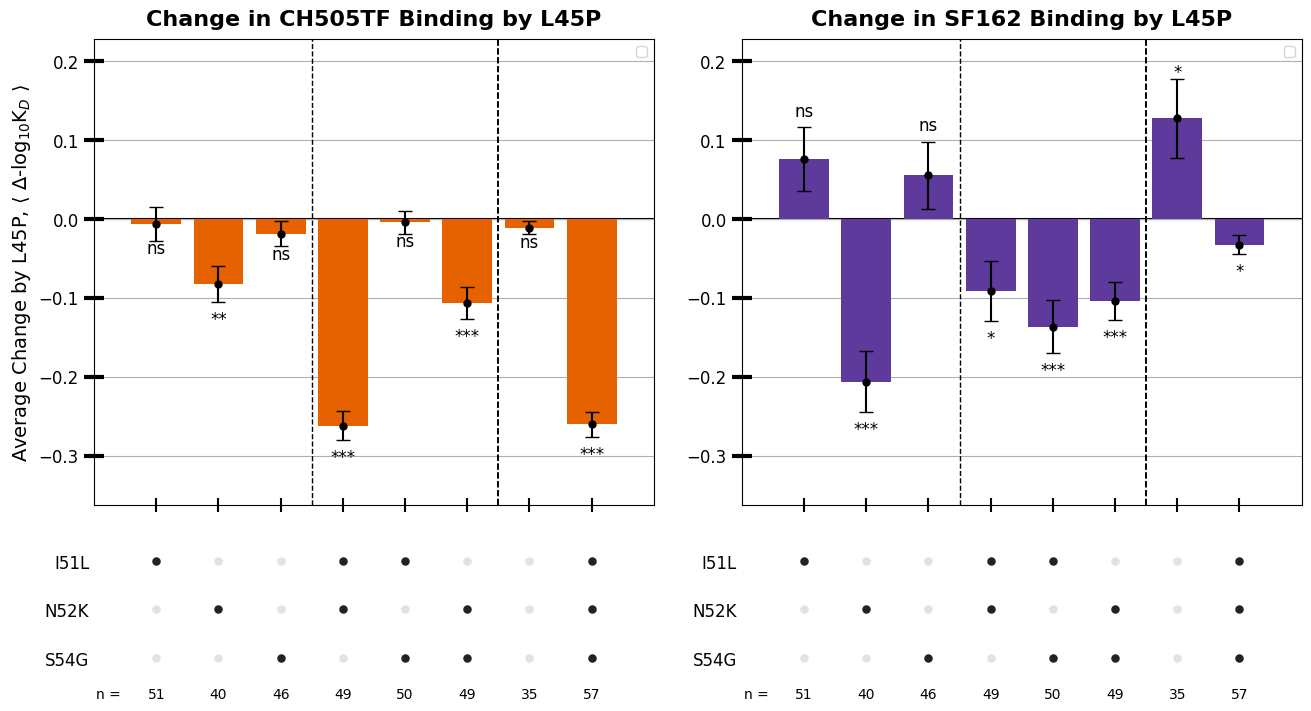

,term,antigen,mean,mature,germline,median,distribution,std error,N
0,I51L,CH505TF,-0.153256,"[5.792794179925688, 5.736098884351435, 5.78705...","[5.94758952412205, 5.891884518935925, 5.942653...",-0.154810,"[-0.1547953441963621, -0.15578563458448969, -0...",0.000530,42
1,N52K,CH505TF,-0.242293,"[5.857736768986938, 5.764290384688063, 5.80329...","[6.103077832749386, 6.007003744231044, 6.04779...",-0.245191,"[-0.24534106376244758, -0.24271335954298134, -...",0.001235,44
2,S54G,CH505TF,-0.152700,"[5.702039811564042, 5.738491455417286, 5.73745...","[5.856594377638024, 5.893704001936287, 5.89292...",-0.153025,"[-0.15455456607398244, -0.1552125465190013, -0...",0.000563,38
3,"I51L,N52K",CH505TF,-0.275071,"[5.912854595274175, 5.986717134097778, 5.90902...","[6.190787730453348, 6.270131056954782, 6.19285...",-0.276337,"[-0.27793313517917273, -0.2834139228570045, -0...",0.001536,49
4,"I51L,S54G",CH505TF,-0.150295,"[5.726837553411033, 5.759744056048166, 5.79798...","[5.88344831529425, 5.914440830414108, 5.956189...",-0.151373,"[-0.15661076188321665, -0.15469677436594242, -...",0.000831,46
5,"N52K,S54G",CH505TF,-0.243364,"[5.862102868858037, 5.787034726074046, 5.76181...","[6.108150650055638, 6.036742981839555, 6.00583...",-0.245080,"[-0.24604778119760073, -0.24970825576550926, -...",0.001023,48
6,None,CH505TF,-0.152636,"[5.670369946207206, 5.707141422720517, 5.69262...","[5.825934521177128, 5.860508421531935, 5.84562...",-0.153367,"[-0.15556457496992238, -0.1533669988114177, -0...",0.000627,23
7,All,CH505TF,-0.276229,"[5.92591805381163, 5.998628034977871, 5.956817...","[6.205481042252655, 6.28166586502664, 6.239087...",-0.277346,"[-0.27956298844102534, -0.2830378300487686, -0...",0.001176,56
8,I51L,SF162,0.003207,"[6.467186751089321, 6.458163958010797, 6.47110...","[6.458087643239852, 6.444290738747344, 6.47064...",0.003494,"[0.00909910784946888, 0.013873219263452974, 0....",0.003004,51
9,N52K,SF162,-0.170399,"[6.574866254666185, 6.472741256007442, 6.48396...","[6.7416710916954194, 6.62421274772307, 6.63050...",-0.159583,"[-0.16680483702923432, -0.15147149171562813, -...",0.004755,40


independent t-test results stored as a csv file
--------- p-values for individual bar -------------
from left to right the significance of each bar
[1.15231502e-68 1.74995772e-64 4.53816085e-62 1.15231502e-68
 2.47887808e-65 5.92292199e-73 1.00327487e-38 7.83877502e-83
 3.15186891e-01 5.27248832e-31 4.88659191e-01 1.25076873e-21
 1.55221551e-12 1.07745823e-25 1.37459024e-01 4.90871574e-12]
---------------------------------------------------
num p = 8


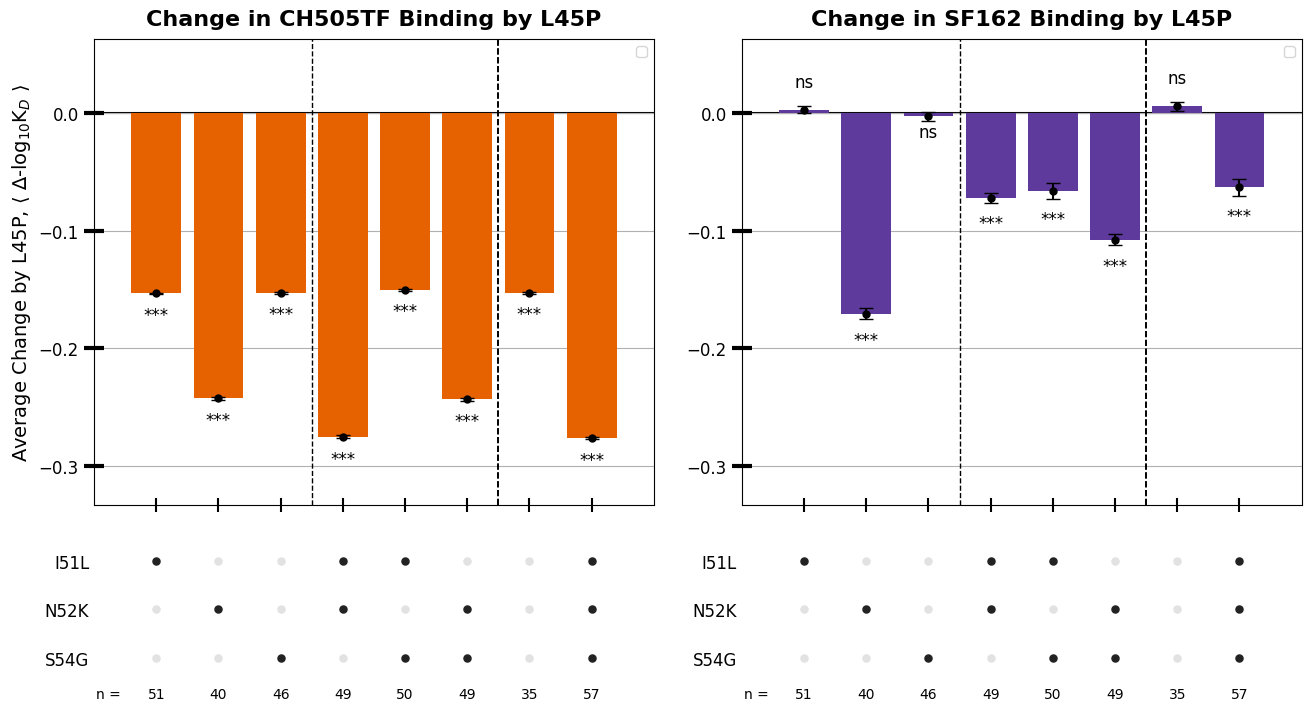

In [ ]:
paired_vi_gen('NIH45-46',token_tobit_updated,[2],[3,4,5],auxiliary_site= [], tick_space = .1,  tobit_col= 'uncensor', panels_identity = 'M',
              auxiliary_identity= None, color_by_antigen= True,save_fig = True,plot_raw_avg = False ,
              save_fig_title = 'Tobit Delta Bar NIH', save_fig_mode = '.png',fig_size = (13,7))

,term,antigen,mean,mature,germline,median,distribution,std error,N
0,A24V,CH505TF,-0.028332,"[7.329965240322965, 6.747418179114638, 7.11611...","[7.448785118043265, 7.033705413410137, 7.18308...",-0.023693,"[-0.11881987772030023, -0.2862872342954983, -0...",0.043106,29
1,S35EI,CH505TF,-0.163183,"[6.78405169444528, 7.272412002983556, 6.763617...","[7.289989388108962, 7.384256177332934, 7.27204...",-0.137140,"[-0.5059376936636824, -0.1118441743493781, -0....",0.049494,26
2,E73G,CH505TF,-0.059731,"[7.120305873293061, 7.124133354030235, 6.86878...","[7.07219036256006, 7.269014624559652, 7.146154...",-0.068093,"[0.04811551073300091, -0.14488127052941735, -0...",0.033389,29
3,S82BN,CH505TF,-0.095394,"[6.552229515437697, 6.9940045033872735, 6.4584...","[7.1895640893882735, 6.729144455330181, 6.9297...",-0.064799,"[-0.6373345739505769, 0.2648600480570922, -0.4...",0.070476,19
4,"A24V,S35EI",CH505TF,-0.121001,"[7.245202072173077, 7.253706469098379, 7.01099...","[7.75939921561821, 7.747106566362186, 7.415781...",-0.107139,"[-0.5141971434451325, -0.49340009726380707, -0...",0.046554,26
5,"A24V,E73G",CH505TF,-0.000759,"[7.43741035537147, 7.400812727127947, 7.221961...","[7.198913232320455, 7.328414104512046, 7.30022...",-0.044595,"[0.23849712305101445, 0.07239862261590169, -0....",0.022350,32
6,"A24V,S82BN",CH505TF,-0.066408,"[7.1814740594810385, 7.056761751553367, 6.9241...","[7.179379051127871, 7.130759416250965, 7.06312...",-0.050011,"[0.002095008353167671, -0.07399766469759772, -...",0.024808,21
7,"S35EI,E73G",CH505TF,0.004645,"[7.450362095139531, 7.565361807478478, 7.48098...","[7.442573585868717, 7.463955589949736, 7.48559...",0.006910,"[0.007788509270813648, 0.10140621752874246, -0...",0.015758,30
8,"S35EI,S82BN",CH505TF,-0.009558,"[7.137494529488027, 7.075936770165667, 7.41771...","[7.361559981969098, 7.2507638800273515, 7.0590...",-0.009340,"[-0.2240654524810708, -0.1748271098616847, 0.3...",0.030832,26
9,"E73G,S82BN",CH505TF,-0.060507,"[7.070492950580867, 6.966711082049111, 7.49996...","[7.322972192433701, 7.080539926012446, 7.03880...",-0.071406,"[-0.2524792418528339, -0.11382884396333548, 0....",0.038296,23


independent t-test results stored as a csv file
--------- p-values for individual bar -------------
from left to right the significance of each bar
[6.44489053e-01 1.37077637e-02 1.59467018e-01 2.97031084e-01
 3.46675937e-02 9.73556359e-01 3.46675937e-02 8.25598346e-01
 8.25598346e-01 2.08073831e-01 5.17103002e-01 8.09094065e-01
 1.37077637e-02 1.93947766e-02 2.74830976e-04 6.09741229e-01
 1.93947766e-02 5.04688341e-03 5.17103002e-01 8.62298079e-01
 3.46675937e-02 6.39090816e-04 5.16145893e-02 2.31337476e-06
 2.29695291e-02 3.46675937e-02 2.22883263e-03 2.74830976e-04
 1.88354930e-01 3.46675937e-02 1.88354930e-01 8.09094065e-01]
---------------------------------------------------
num p = 16


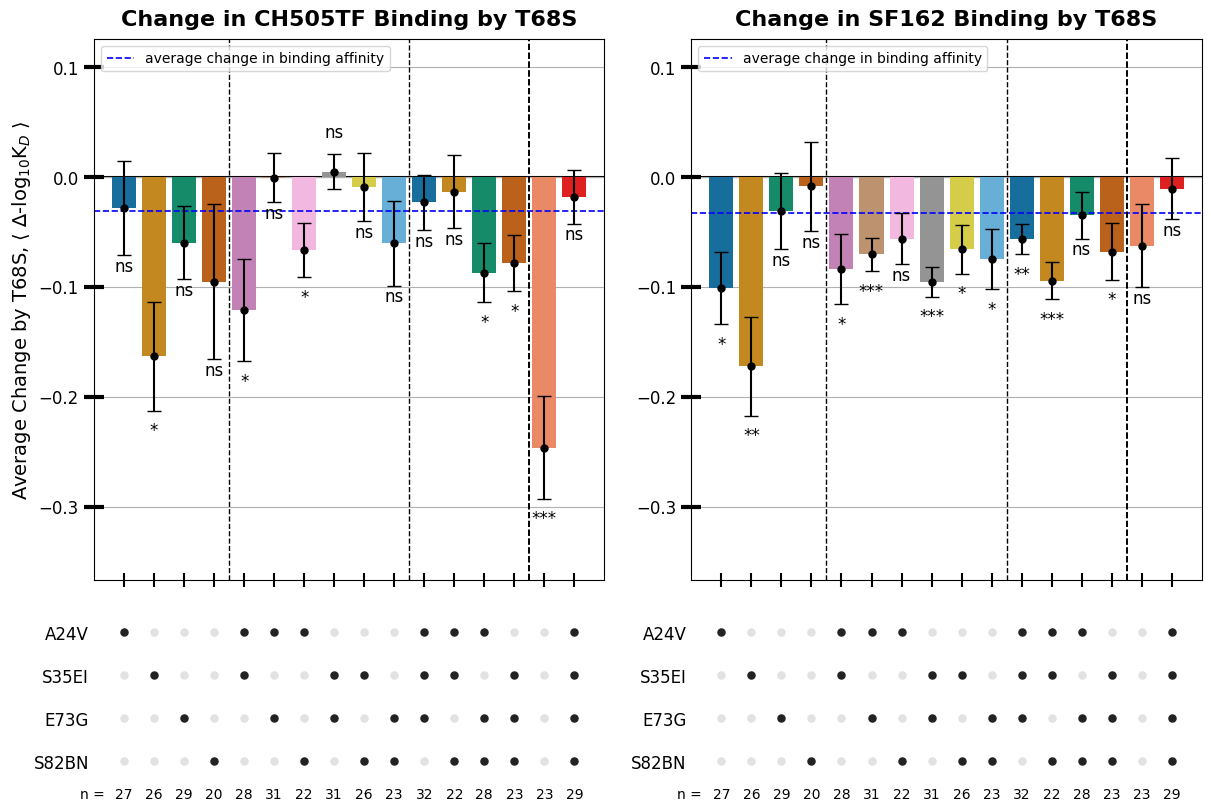

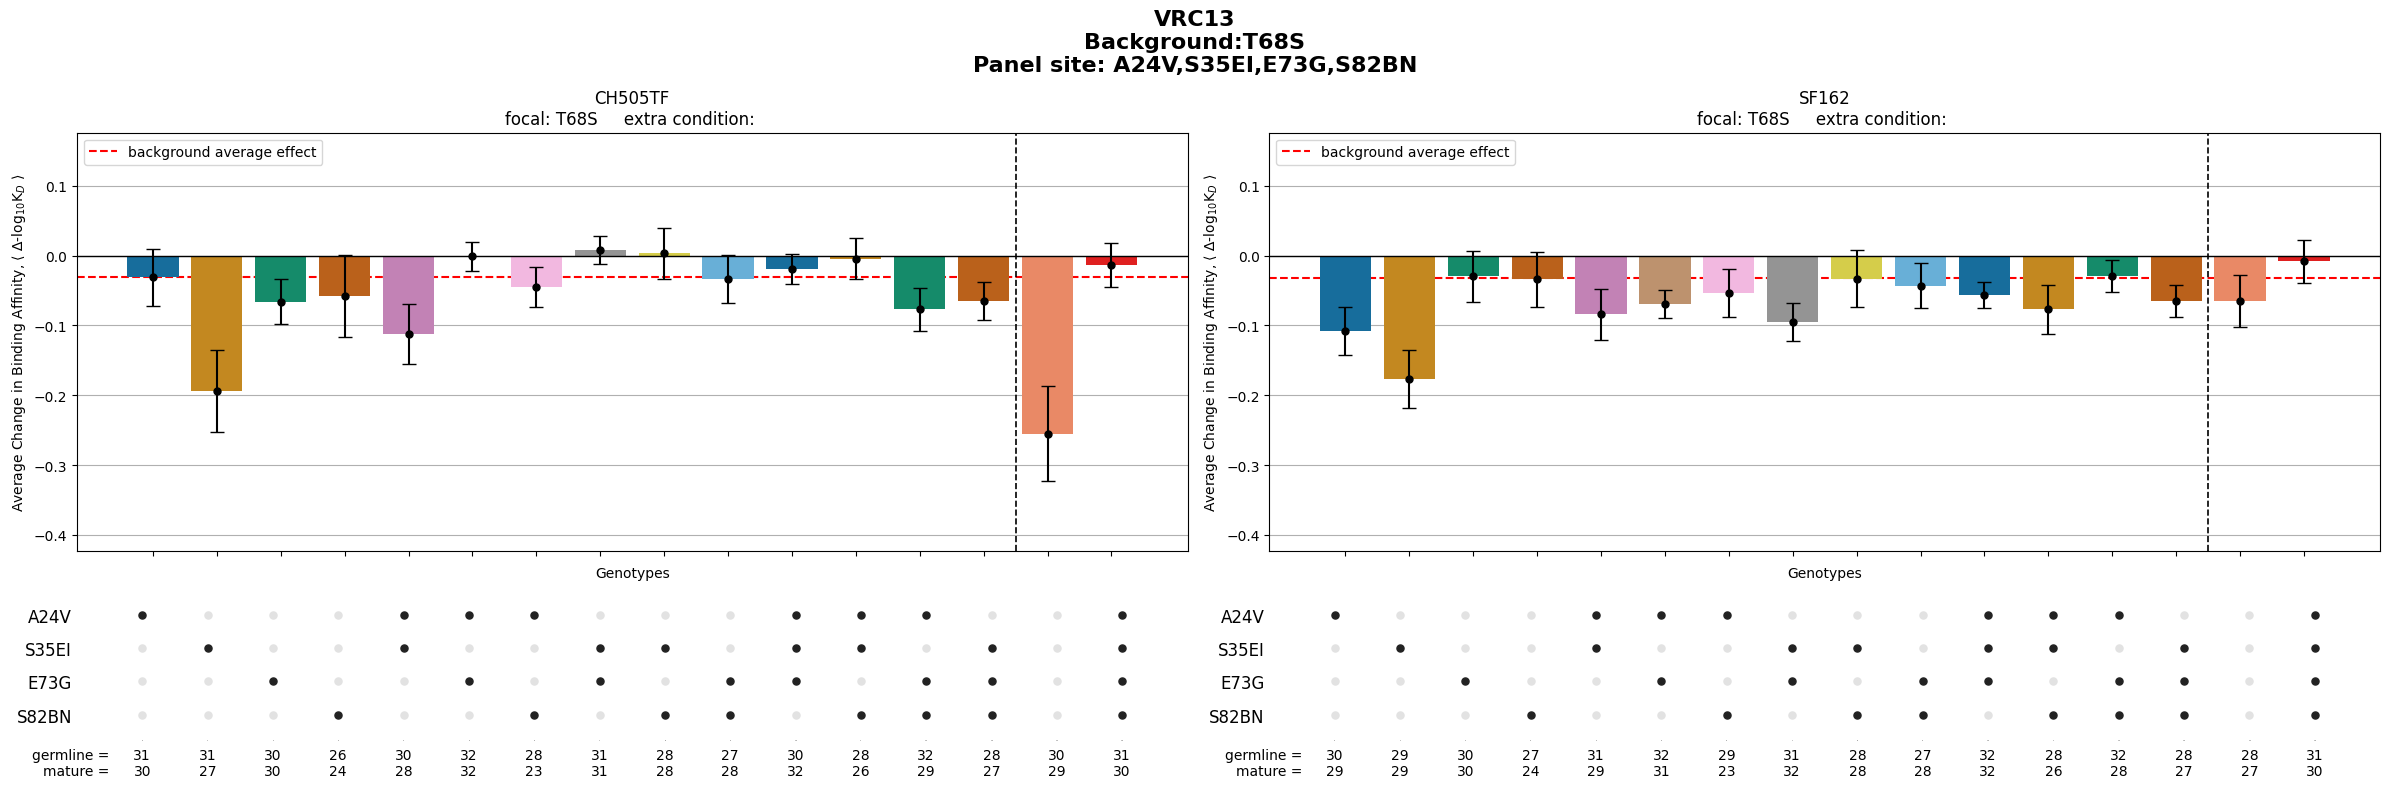

[list(['30\n31', '27\n31', '30\n30', '24\n26', '28\n30', '32\n32', '23\n28', '31\n31', '28\n28', '28\n27', '32\n30', '26\n28', '29\n32', '27\n28', '29\n30', '30\n31'])
 list(['29\n30', '29\n29', '30\n30', '24\n27', '29\n31', '31\n32', '23\n29', '32\n31', '28\n28', '28\n27', '32\n32', '26\n28', '28\n32', '27\n28', '27\n28', '30\n31'])]


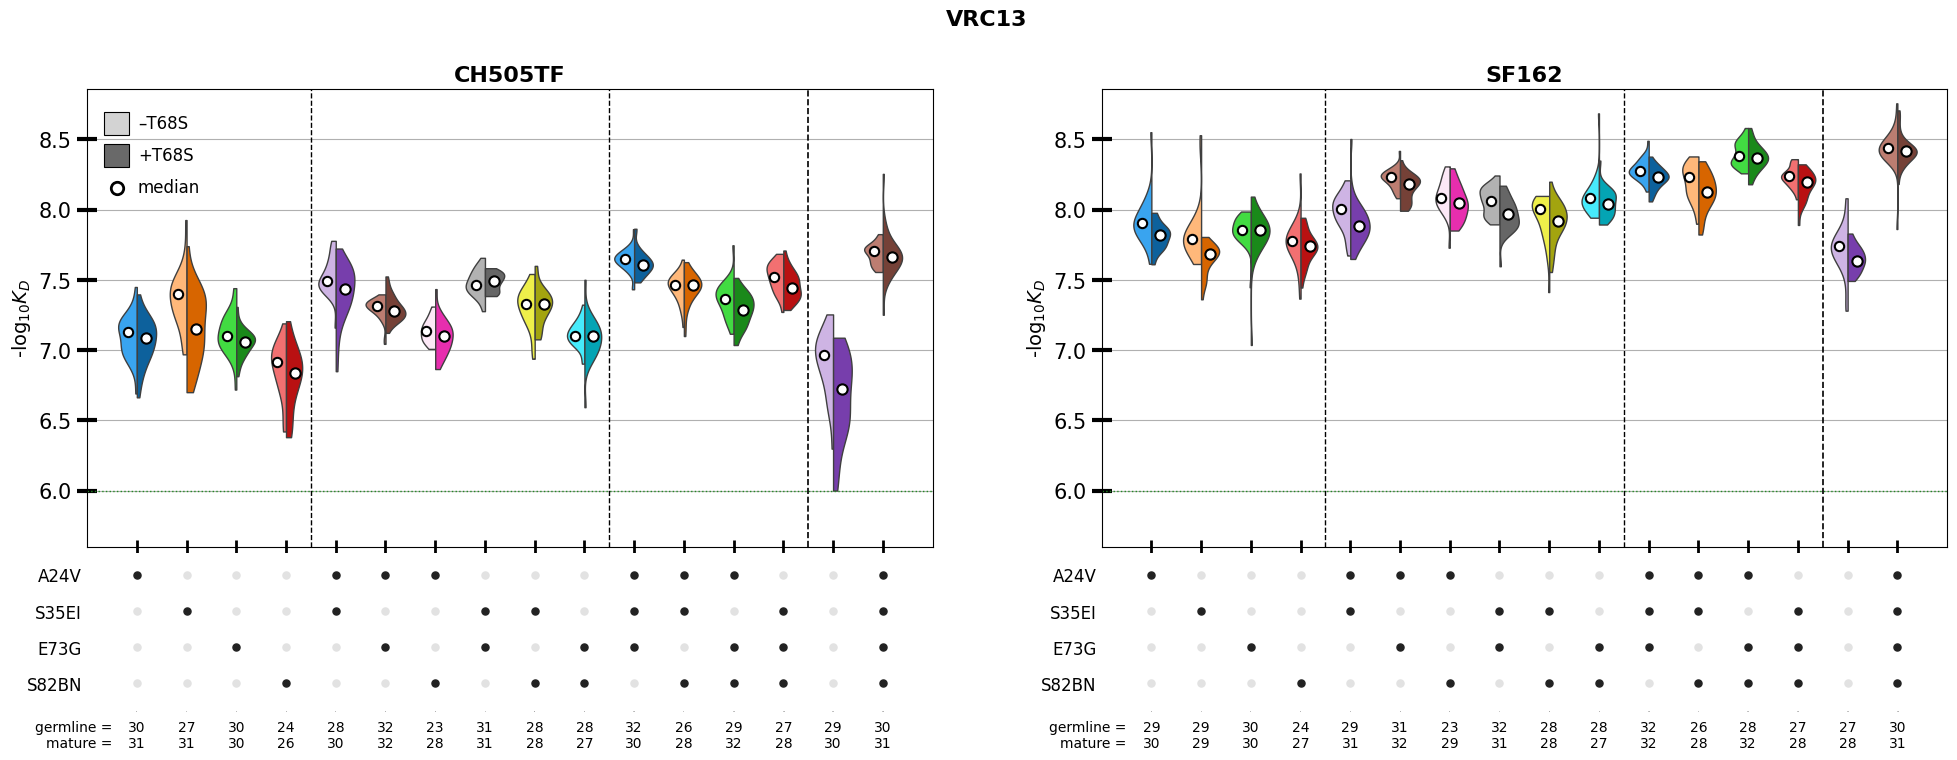

In [ ]:
paired_vi_gen(bnab = 'VRC13',df_function=token_kds,background=[5],panels=[1,3,7,9],panels_identity='M',tobit_col=None,
              tick_space = 0.1,
              plot_tobit = False,
              plot_raw_avg = True,
              save_fig = True,
              save_fig_title = 'paired 68')

plot_delta('VRC13',token_kds,[5],[1,3,7,9],auxiliary_site= [], auxiliary_identity=None, save_fig = True, save_fig_title = 'solo T68S')
plot_graph('VRC13',token_kds,[5],[1,3,7,9],save_fig = False)

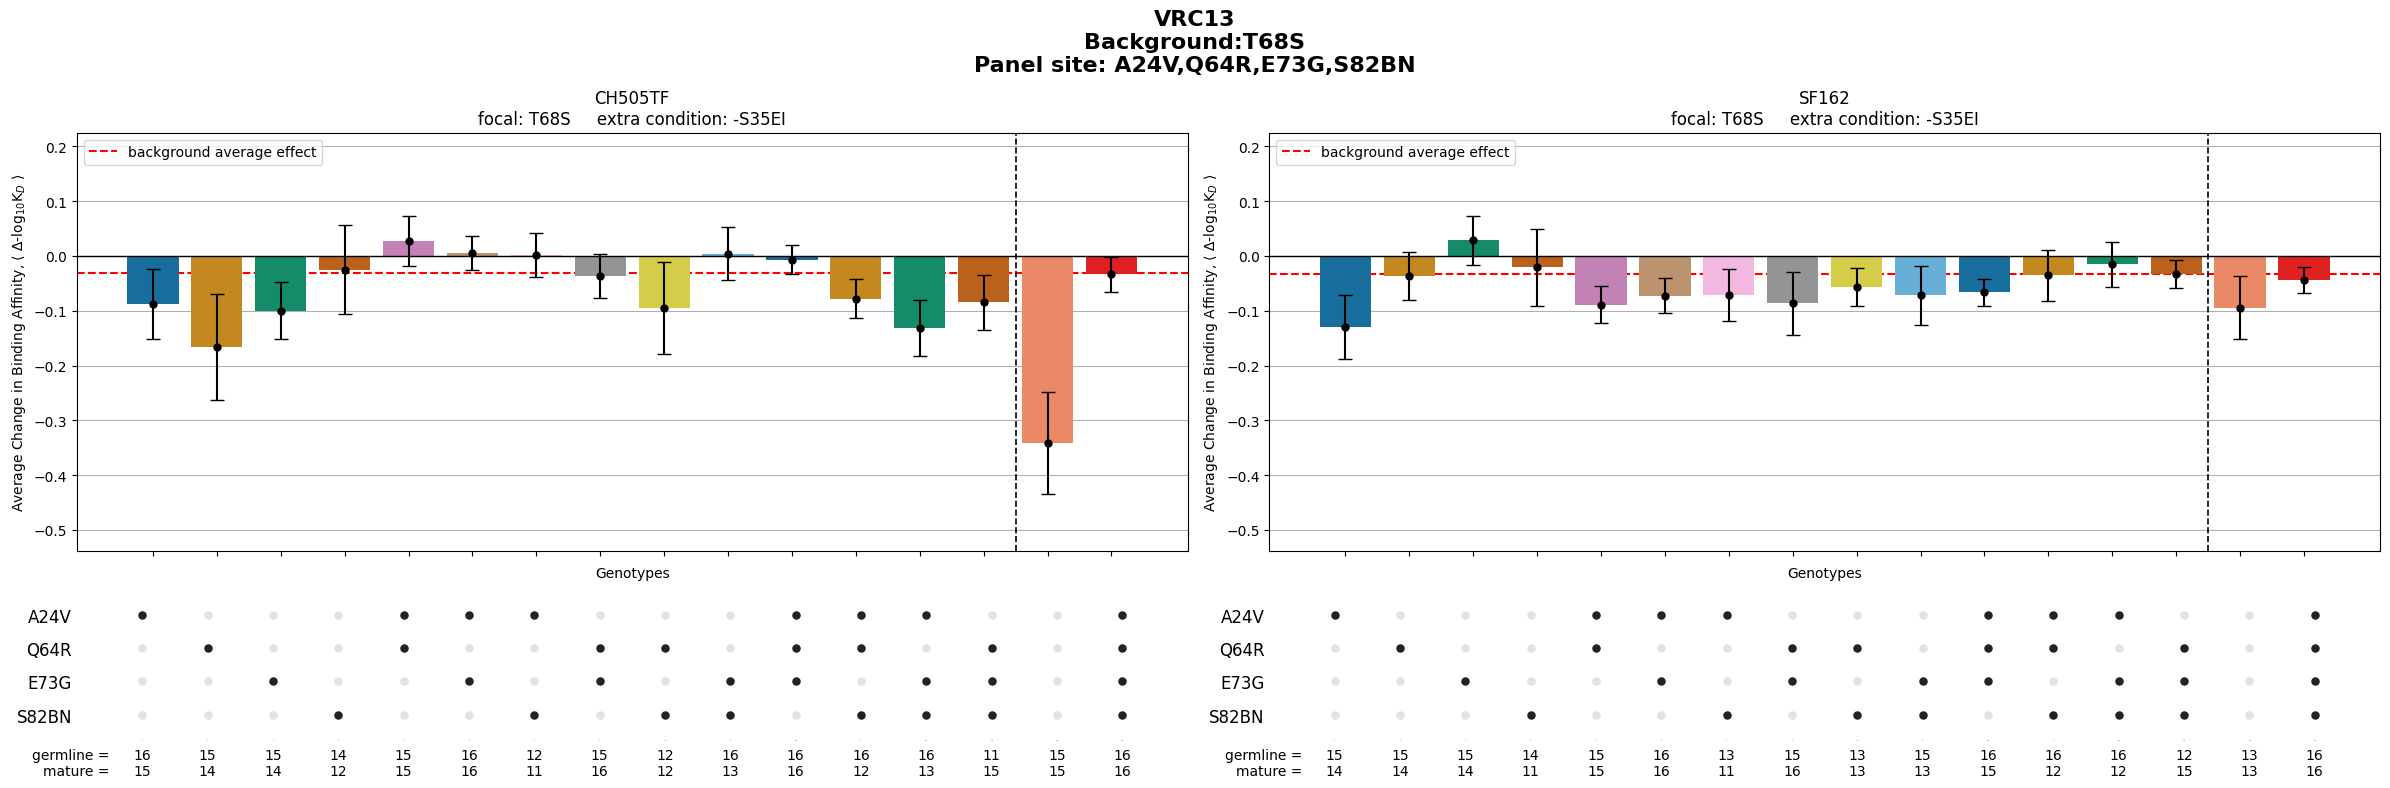

[list(['15\n16', '14\n15', '14\n15', '12\n14', '15\n15', '16\n16', '11\n12', '16\n15', '12\n12', '13\n16', '16\n16', '12\n16', '13\n16', '15\n11', '15\n15', '16\n16'])
 list(['14\n15', '14\n15', '14\n15', '11\n14', '15\n15', '16\n16', '11\n13', '16\n15', '13\n13', '13\n15', '15\n16', '12\n16', '12\n16', '15\n12', '13\n13', '16\n16'])]


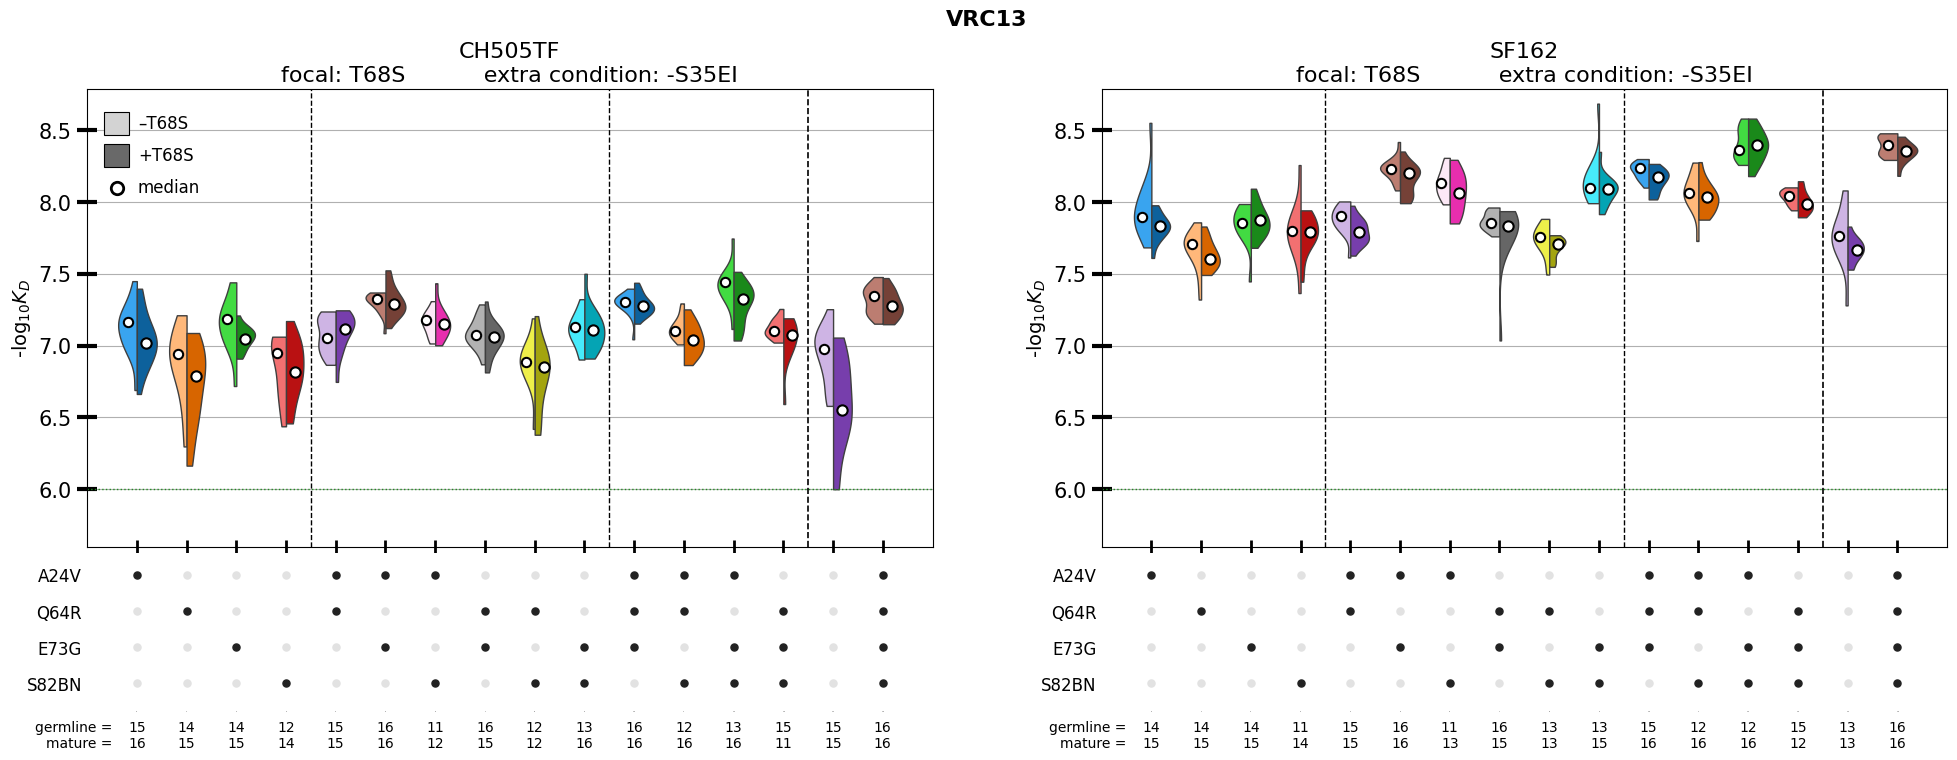

In [ ]:
plot_delta('VRC13',token_kds,[5],[1,4,7,9],auxiliary_site= [3], auxiliary_identity='G', save_fig = False, save_fig_title = 'Epistatic Interaction of T68S')
plot_graph('VRC13',token_kds,[5],[1,4,7,9],auxiliary_site= [3], auxiliary_identity='G', save_fig = False, save_fig_title = 'Epistatic Interaction of T68S')


### **Plot Plot**

,term,antigen,mean,mature,germline,median,distribution,std error,N
0,V18M,CH505TF,0.268313,"[6.210729849474583, 6.0, 6.0, 6.51050850653692...","[6.0, 6.131931521960967, 6.730219296232844, 6....",0.341232,"[0.21072984947458284, -0.1319315219609667, -0....",0.072272,22
1,L45P,CH505TF,0.237036,"[6.080529201522571, 6.956328382784679, 6.0, 6....","[6.0, 6.317895170245814, 6.0, 6.07448776198444...",0.106898,"[0.08052920152257137, 0.6384332125388648, 0.0,...",0.057983,26
2,G56A,CH505TF,0.343880,"[6.582296066688739, 6.32295857441004, 6.326149...","[6.0, 6.134111039426899, 6.0, 6.0, 6.0, 6.0180...",0.256096,"[0.5822960666887393, 0.18884753498314133, 0.32...",0.053686,28
3,L108P,CH505TF,0.254871,"[6.143698920957121, 6.000897259547215, 6.10794...","[6.050761870595263, 6.133603532723473, 6.0, 6....",0.159831,"[0.09293705036185784, -0.13270627317625827, 0....",0.054328,25
4,"V18M,L45P",CH505TF,0.242419,"[6.0, 6.0, 6.0, 6.223785275739553, 6.535627253...","[6.3780297666943415, 6.0, 6.0, 6.0, 6.02623655...",0.223785,"[-0.3780297666943415, 0.0, 0.0, 0.223785275739...",0.072417,21
5,"V18M,G56A",CH505TF,0.189576,"[6.0, 6.0, 6.4708625269137245, 6.8156781085447...","[6.404001260624405, 6.024086200686705, 6.00102...",0.195120,"[-0.4040012606244048, -0.024086200686705084, 0...",0.076880,17
6,"V18M,L108P",CH505TF,0.227182,"[6.038109605233716, 6.0, 6.3390159414714855, 6...","[6.407449837262564, 6.0, 6.014512402021914, 6....",0.261244,"[-0.3693402320288479, 0.0, 0.3245035394495712,...",0.068271,26
7,"L45P,G56A",CH505TF,0.335043,"[6.516945174444359, 7.226036674126442, 6.04407...","[6.0, 6.560757993584647, 6.0, 6.0, 6.942550686...",0.349951,"[0.5169451744443592, 0.6652786805417952, 0.044...",0.068943,18
8,"L45P,L108P",CH505TF,0.337493,"[6.3515601491813, 6.04800755081061, 6.0, 6.087...","[6.0, 6.0, 6.029256383277934, 6.12739403111852...",0.355839,"[0.3515601491813003, 0.0480075508106097, -0.02...",0.072788,18
9,"G56A,L108P",CH505TF,0.288615,"[6.2865462008147155, 6.368116628000967, 6.1806...","[6.0, 6.0, 6.186384160731423, 6.16465289311287...",0.358396,"[0.2865462008147155, 0.36811662800096734, -0.0...",0.066827,21


independent t-test results stored as a csv file
--------- p-values for individual bar -------------
from left to right the significance of each bar
[2.10481259e-03 7.75389293e-04 5.27486331e-06 2.85182415e-04
 4.41002787e-03 3.03165741e-02 3.91722128e-03 4.49116579e-04
 6.23454739e-04 7.39905852e-04 1.25048067e-03 4.59185162e-04
 1.04344231e-02 7.39905852e-04 5.27486331e-06 6.07763042e-03
 5.11230919e-06 5.27486331e-06 1.74864905e-05 1.45899711e-04
 8.56809174e-05 2.76825763e-04 1.81928147e-07 6.95400385e-04
 2.58061355e-08 4.41002787e-03 1.98066701e-03 1.42864670e-05
 2.06924972e-03 2.75267611e-03 2.88619399e-05 4.15961883e-02]
---------------------------------------------------
num p = 16


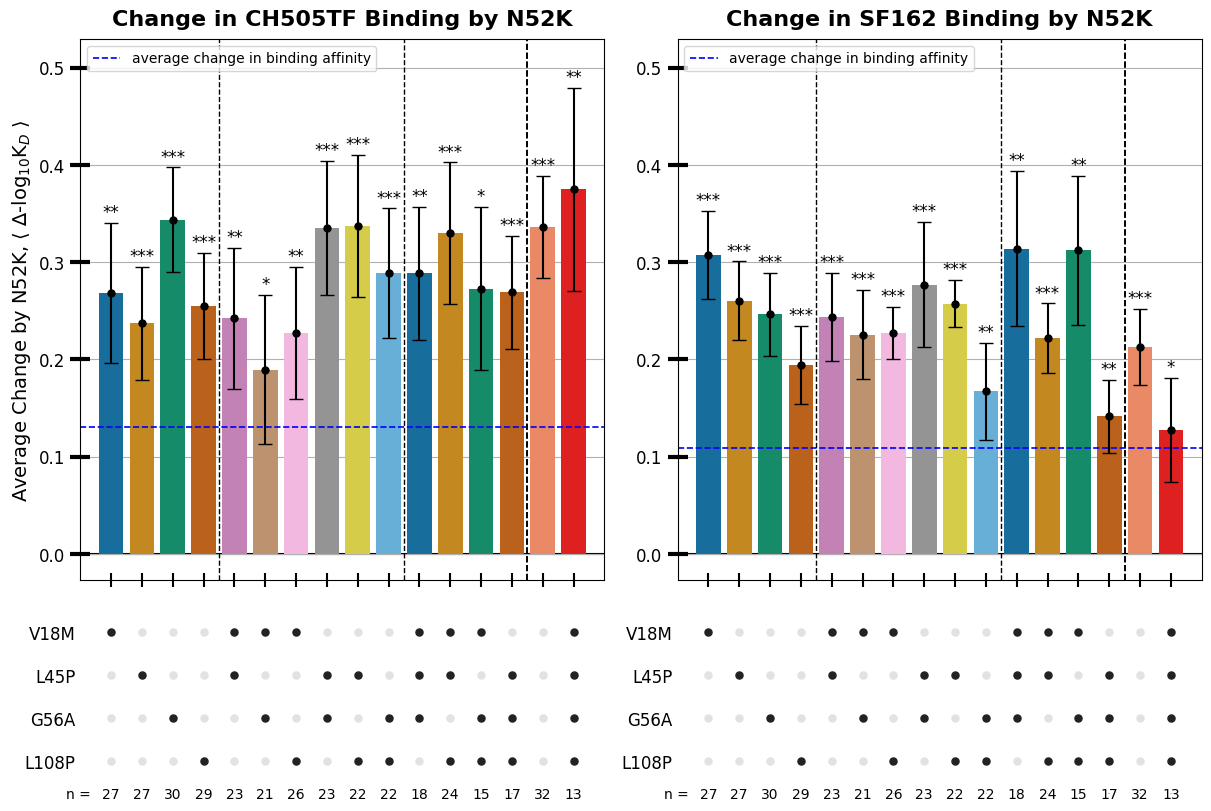

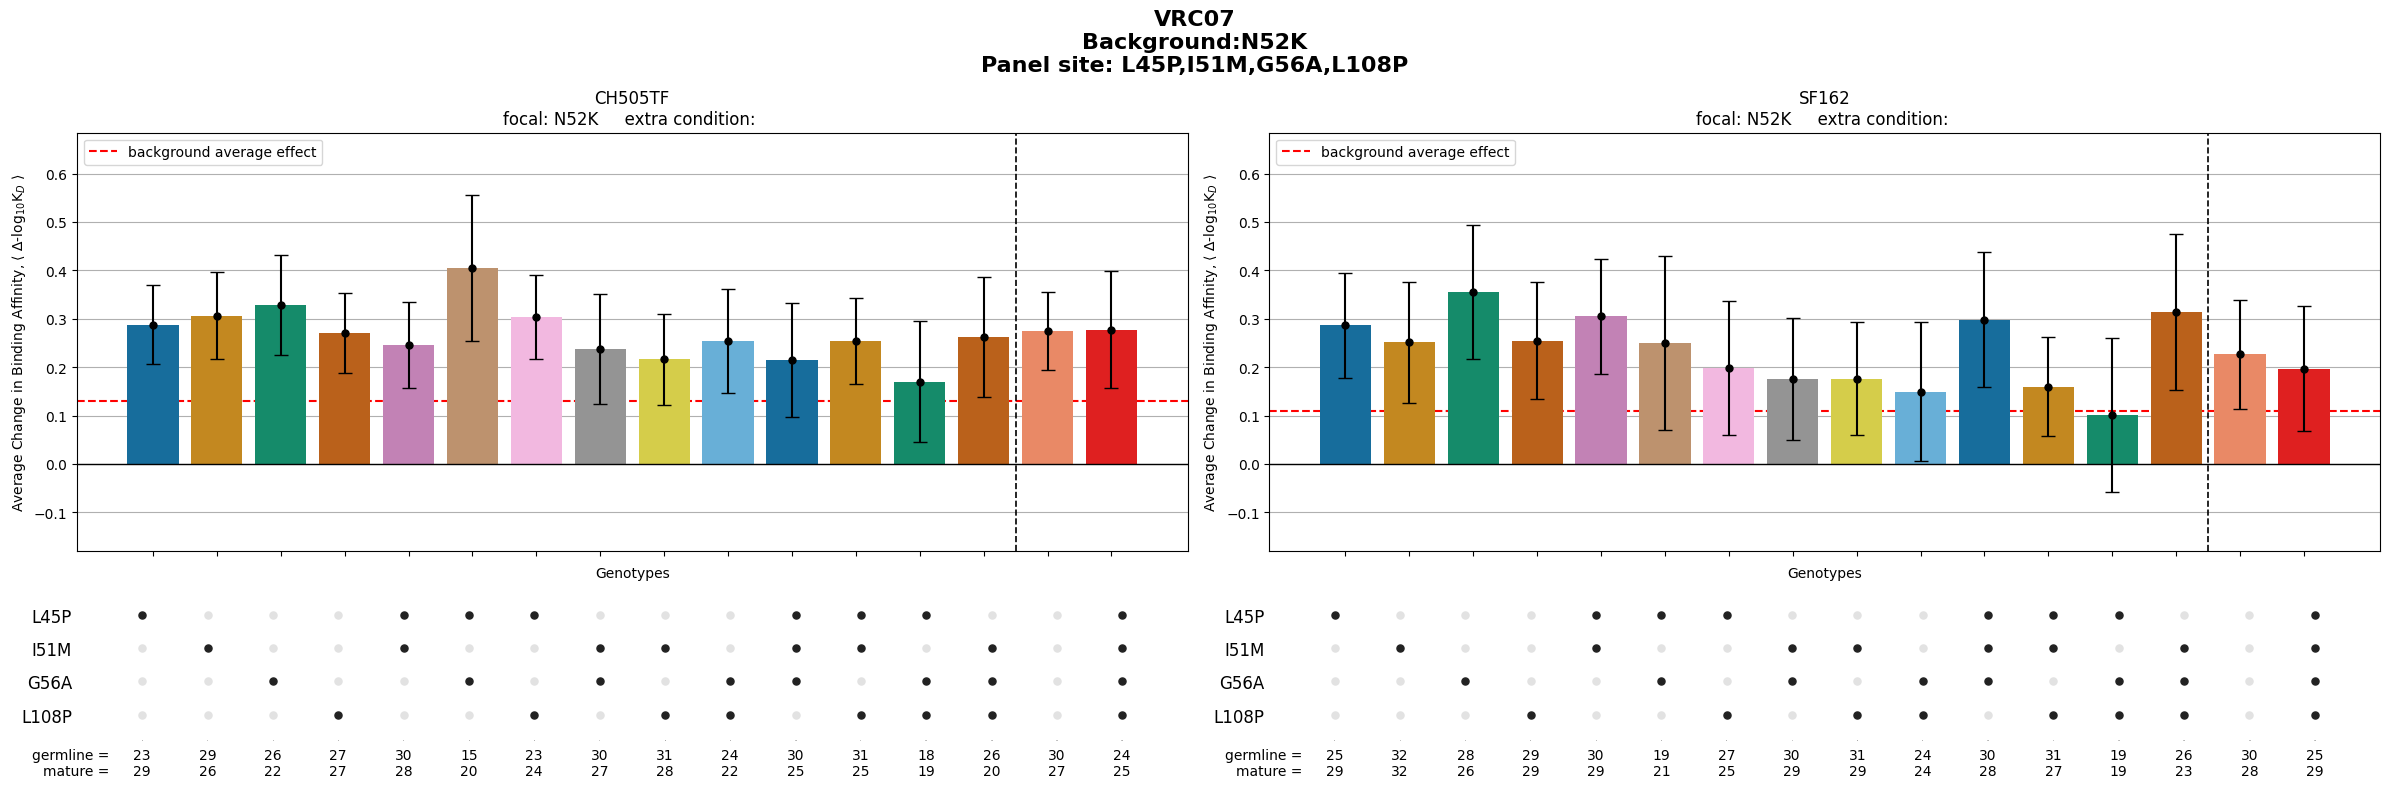

[list(['29\n23', '26\n29', '22\n26', '27\n27', '28\n30', '20\n15', '24\n23', '27\n30', '28\n31', '22\n24', '25\n30', '25\n31', '19\n18', '20\n26', '27\n30', '25\n24'])
 list(['29\n25', '32\n32', '26\n28', '29\n29', '29\n30', '21\n19', '25\n27', '29\n30', '29\n31', '24\n24', '28\n30', '27\n31', '19\n19', '23\n26', '28\n30', '29\n25'])]


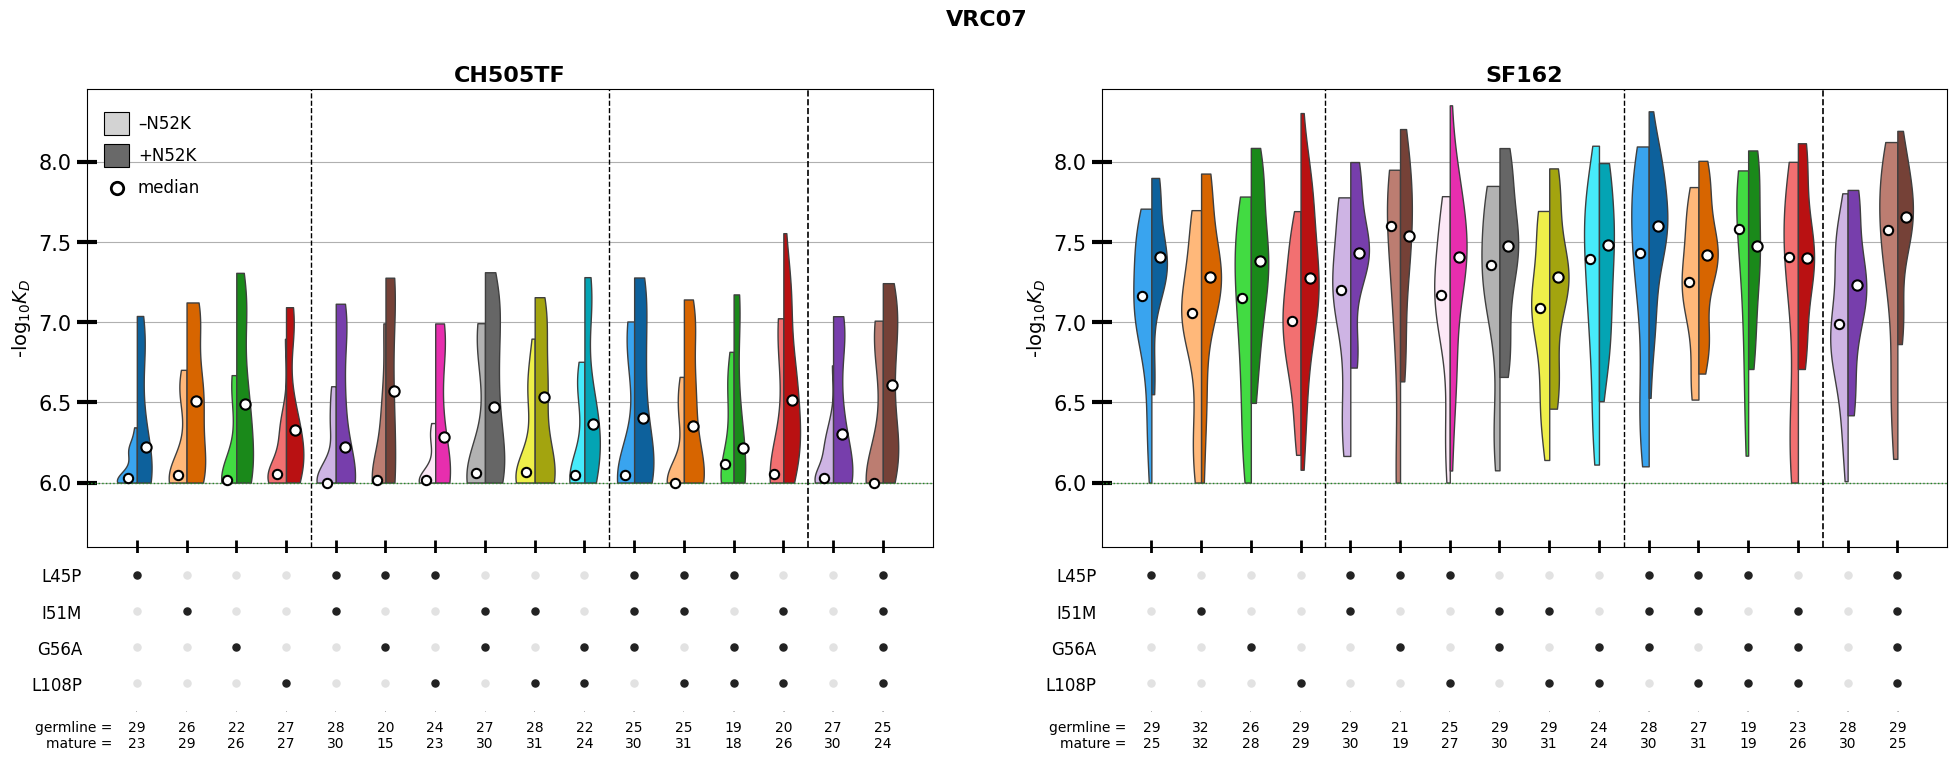

In [ ]:
paired_vi_gen(bnab = 'VRC07',df_function=token_kds,background=[5],panels=[1,3,7,9],panels_identity='M',tobit_col=None,
              tick_space = 0.1,
              plot_tobit = False,
              plot_raw_avg = True,
              save_fig = False,
              save_fig_title = '')

plot_delta('VRC07',token_kds,[5],[3,4,7,9],auxiliary_site= [], auxiliary_identity=None, save_fig = False, save_fig_title = 'Epistatic Interaction of T68S')
plot_graph('VRC07',token_kds,[5],[3,4,7,9],save_fig = False)

### **None and All Only Panels**

In [ ]:
from matplotlib import gridspec
def none_all(bnab: str,
             df_function,
             background: list,
             panels: list,
             panels_identity: str = 'M',
             tobit_col: str = None,
             auxiliary_site: list = None,
             auxiliary_identity: str = None,
             plot_vi: bool = True,
             plot_tobit: bool = False,
             plot_raw_avg: bool = True,
             fig_size: tuple = (12,8),
             save_fig: bool = False,
             save_fig_title: str = '',
             save_fig_format: str = 'png'):

  '''''
    bnab = 'bnab name'
    df_function = token_tobit or token_kds, chooses which type of Kd values you want to pull. For raw, use token_kds.
                  If using token_tobit, also provide a tobit_col designation (censor or uncensor)
    panels = list of sites in panel on x-axiseg. [1,2,3,5]
    panels_identity = 'M' or 'G'. Defaults to 'M' But change to 'G' if you wish the x-axis genotypes to hold the set of sites germline
    auxiliary_site = list of site(s) that to impose an additional condition. This argument is optional. Defaults to None without input
    auxiliary_identity = 'M' or 'G'
    tobit_col = 'censor' or 'uncensor' depending on which type of tobit values you want. Only pass this argumet when df_function = token_tobit

    tick_space = specify tick gaps on y-axis
    plot_vi = plots violins of deltas instead of bars if changed to True
    plot_tobit = plots a dashed line of tobit additive coefficient
    plot_raw_avg = plots a dashed line of average change in binding affinity
    save_fig = True or False. Assign True to save figure
    save_fig_title = If save_fig is True, also pass this argument with desired title header
    save_fig_format = .png or .pdf

    return_mode = returns the data df instead of plotting the graph if True

    '''''

  none_all_terms = ['None', 'All']
  antigen_names = ['CH505TF', 'SF162']

  custom_colors = [
    "#E69A63", "#E66100",  # CH None: germline-mature
    "#E69A63", "#E66100",  # CH All: germline-mature
    "#9C88C2", "#5D3A9B",  # SF None: germline-mature
    "#9C88C2", "#5D3A9B" ]  # SF All: germline-mature

  custom_colors_bar = ["#E66100", "#E66100","#5D3A9B", "#5D3A9B"]
  convert_label = mutation_convert_label(meta_dict[bnab])

  def t_test(antigen, g_name, test_df_in):
    '''''
    Takes in the antigen and the group name (dictionary key) to compute the
    p-value from a paired t-test of the germline and mature groups.

    returns t, p, and the number of datapoints
    '''''
    antigen_filtered = test_df_in[test_df_in['antigen'] == antigen].copy()
    g1 = np.array(antigen_filtered[antigen_filtered['term'] == g_name]['germline'].values[0])
    g2 = np.array(antigen_filtered[antigen_filtered['term'] == g_name]['mature'].values[0])
    t, p = sp.stats.ttest_rel(g1, g2)
    n = len(g1)
    return t, p, n

  def t_test_ind(antigen, test_df_in):
    '''''
    Takes in the antigen and the group name (dictionary key) to compute the
    p-value from a paired t-test of the germline and mature groups.

    returns t, p, and the number of datapoints
    '''''
    antigen_filtered = test_df_in[test_df_in['antigen'] == antigen].copy()
    g1 = np.array(antigen_filtered[antigen_filtered['term'] == 'None']['distribution'].values[0])
    g2 = np.array(antigen_filtered[antigen_filtered['term'] == 'All']['distribution'].values[0])
    print(len(g1))
    t, p = sp.stats.ttest_ind(g1, g2)
    n = len(g1)
    return t, p, n


  ##### ---------------------------------------------------------------
  ##### Part 1 (paired_vi_gen half): mean delta affinity change, None/All only
  ##### ---------------------------------------------------------------
  CH_result, SF_result, CHparam, SFparam, CH_bg_avg_delta, SF_bg_avg_delta, combinatorial_l = data_gen_new(
      bnab, df_function, background, 'G', panels, panels_identity,
      auxiliary_site, auxiliary_identity, tobit_col)

  kds_CH = df_function(bnab, 'CH505TF')
  kds_SF = df_function(bnab, 'SF162')
  difference_df_temp = pd.DataFrame({})

  for i, data_set, kds_df in zip([0, 1], [CH_result, SF_result], [kds_CH, kds_SF]):
    for key in none_all_terms:
      df = data_set[key].copy()
      df.reset_index(inplace=True)
      difference_l = []
      germline_l = []
      mature_l = []
      for idx, row in df.iterrows():
        m_genotype = row['genotype_tokens']
        for bs in background:
          m_genotype = m_genotype[:bs] + 'M' + m_genotype[bs + 1:]

        mature_Kd = kds_df[kds_df['genotype_tokens'] == m_genotype].reset_index()
        if not mature_Kd.empty:
          difference = mature_Kd['nlog10_Kd'] - row['nlog10_Kd']
          difference_l.append(float(difference))
          germline_l.append(float(row['nlog10_Kd']))
          mature_l.append(float(mature_Kd['nlog10_Kd']))
        else:
          pass

      num_dpoint = len(difference_l)
      df_temp = pd.DataFrame({'term': key,
                               'antigen': ('CH505TF' if i == 0 else 'SF162'),
                               'mean': np.mean(difference_l) if num_dpoint > 0 else np.nan,
                               'mature': [mature_l],
                               'germline': [germline_l],
                               'median': np.median(difference_l) if num_dpoint > 0 else np.nan,
                               'distribution': [difference_l],
                               'std error': (np.std(difference_l) / np.sqrt(num_dpoint)) if num_dpoint > 0 else np.nan,
                               'N': num_dpoint})
      difference_df_temp = pd.concat([difference_df_temp, df_temp])

  difference_df_temp.reset_index(drop=True, inplace=True)
  ##### ---------------------------------------------------------------
  ##### Part 2 (plot_graph half): germline vs mature raw KD, None/All only
  ##### ---------------------------------------------------------------
  bgG_CH, bgG_SF, _ = data_gen(bnab, df_function, background, 'G', panels, panels_identity,
                                auxiliary_site, auxiliary_identity, tobit_col)
  bgM_CH, bgM_SF, _ = data_gen(bnab, df_function, background, 'M', panels, panels_identity,
                                auxiliary_site, auxiliary_identity, tobit_col)

  # store in list form
  dicG_l = [bgG_CH, bgG_SF]
  dicM_l = [bgM_CH, bgM_SF]
  # cut out unnecessay keys
  for i in range(2):
    dicG_l[i] = {k: dicG_l[i][k] for k in none_all_terms if k in dicG_l[i]}
    dicM_l[i] = {k: dicM_l[i][k] for k in none_all_terms if k in dicM_l[i]}


  split_vi_df = pd.DataFrame({ })
  for i in range(2):
    dic_g = dicG_l[i]
    dic_m = dicM_l[i]
    g_df = pd.DataFrame({k: pd.Series(v) for k, v in dic_g.items()}).melt(var_name='sites', value_name='Kd')
    g_df = g_df.assign(identity='germline',
                       antigen = ('CH505TF' if i == 0 else 'SF162'))
    m_df = pd.DataFrame({k: pd.Series(v) for k, v in dic_m.items()}).melt(var_name='sites', value_name='Kd')
    m_df = m_df.assign(identity='mature',
                       antigen = ('CH505TF' if i == 0 else 'SF162'))

    split_vi_df = pd.concat([split_vi_df, g_df, m_df]).reset_index(drop=True)
  split_vi_df = split_vi_df[split_vi_df['sites'].isin(none_all_terms)].copy()

  ##### ---------------------------------------------------------------
  ##### Figure: 1 row x 2 columns -- one subplot per antigen
  ##### ---------------------------------------------------------------
  fig, axes = plt.subplots(2, 2, figsize= fig_size,

                          height_ratios= (1.5,0.5))
  axes = axes.flatten()
  ax = axes[0]

  # -------- plot_split on left (plot_graph half) --------
  ## generate label on the split_vi_df
  split_vi_df['x_label'] = split_vi_df['antigen'] + ' ' + split_vi_df['sites']

  if plot_vi:
    sns.violinplot(ax=ax, data=split_vi_df, x= 'x_label', y='Kd', hue='identity',
                    split=True, inner='quart', density_norm='count', cut=0,saturation = 1,
                    linewidth=1)


    # 4. Iterate through the violins and overwrite their faces
    violins = ax.findobj(PolyCollection)
    for violin, color in zip(violins, custom_colors):
        violin.set_facecolor(color)

    handles1, labels1 = ax.get_legend_handles_labels()
    if ax.legend_ is not None:
      ax.legend_.remove()

  else:
    sns.stripplot(ax=ax, data=split_vi_df, x='x_label', y='Kd', hue='identity',
                    palette='muted', jitter=.3, dodge=True, zorder=5)
    handles1, labels1 = ax.get_legend_handles_labels()
    if ax.legend_ is not None:
      ax.legend_.remove()

  ax.set_xlabel(' ')
  ax.set_ylabel(r'-log$_{10}K_{D}$ (germline / mature)', fontsize=12)

  # find medians
  medians = np.zeros([2,4])
  for idx, label_unique in enumerate(split_vi_df['x_label'].unique()):
    median_g = np.nanmedian(split_vi_df[(split_vi_df['x_label'] == label_unique) & (split_vi_df['identity'] == 'germline')]['Kd'])
    median_m = np.nanmedian(split_vi_df[(split_vi_df['x_label'] == label_unique) & (split_vi_df['identity'] == 'mature')]['Kd'])
    medians[:,idx] = [median_g, median_m]
  medians = medians.flatten()
  # find N for each violin
  num_dpoint = np.zeros([2,4])
  for idx, label_unique in enumerate(split_vi_df['x_label'].unique()):
    num_dpoint_g = len(split_vi_df[(split_vi_df['x_label'] == label_unique) & (split_vi_df['identity'] == 'germline')]['Kd'])
    num_dpoint_m = len(split_vi_df[(split_vi_df['x_label'] == label_unique) & (split_vi_df['identity'] == 'mature')]['Kd'])
    num_dpoint[:,idx] = [num_dpoint_g, num_dpoint_m]

  medians_x_pos = np.concatenate((np.array(list(range(4)))-0.2, np.array(list(range(4)))+0.2))
  ax.set_xticks(list(range(4)))
  ax.set_xticklabels([])
  ax.scatter(x = medians_x_pos, y = medians, marker = 'o', s = 70, color = 'white', edgecolors = 'k',  linewidths = 2, label = 'Median', zorder= 3 )
  max_val_rounded = math.ceil(2*np.max(split_vi_df['Kd']))/2+.5
  ax.set_yticks(np.arange(6,max_val_rounded,.5))
  ax.tick_params(axis = 'y', direction = 'inout',length = 15, width = 2,labelsize = 12)
  ax.tick_params(axis = 'x', direction = 'inout', length = 10, width = 1.5)
  ax.axhline(y= 6, color = 'k', linewidth = '1.2', linestyle = ':')
  ax.set_xlim(-.5,3.5)
  ax.set_xlabel(' ')
  ax.set_ylim(bottom = None, top = max_val_rounded+.1)
  ax.axvline(x = 1.5, linestyle = '--', color = 'k', linewidth = 1.2)
  ax.grid(axis = 'y')
  ax.set_axisbelow(True)

  ## print medians ##
  print('--- medians from left to right ----')
  for idx, median_val in enumerate(medians):
    if idx < 4:
      print(f'germline: {median_val}')
    if idx >= 4:
      print(f'mature: {median_val}')
  print('-----------------------------------')
  ###### ------------------------- delta bars
  ax = axes[1]
  difference_df_temp['x_label'] = difference_df_temp['antigen'] + ' ' + difference_df_temp['term']
  sns.barplot(ax=ax, data=difference_df_temp, x='x_label', y='mean', palette= custom_colors_bar, width = .5, saturation = 1)
  ax.errorbar(x=difference_df_temp['x_label'], y=difference_df_temp['mean'], yerr=difference_df_temp['std error'],
              fmt='o', markersize=5, color='k', capsize=5)

  ax.set_xticklabels([])
  ax.set_xlabel(' ')
  focal_site = [f'{convert_label[f'site_{bs}']}' for bs in background]
  focal_site = ','.join(focal_site)
  ax.set_ylabel(f'Average Change by {focal_site}, ' + r'$\langle$ ∆-log$_{10}K_{D}$ $\rangle$', fontsize=12)
  ax.axhline(y= 0, color = 'k')
  ax.set_xlim(-.5,3.5)
  min_val = np.min(difference_df_temp['mean']) - np.max(difference_df_temp['std error'])
  max_val = np.max(difference_df_temp['mean']) +  np.max(difference_df_temp['std error'])
  ax.set_yticks(np.arange(-2,2,.1))
  ax.set_ylim(min_val-.1,max_val)
  ax.tick_params(axis = 'y', direction = 'inout',length = 15, width = 2,labelsize = 12)
  ax.tick_params(axis = 'x', direction = 'inout', length = 10, width = 1.5)
  ax.axvline(x = 1.5, linestyle = '--', color = 'k', linewidth = 1.2)
  ax.grid(axis = 'y')
  ax.set_axisbelow(True)

  if plot_tobit:
      ax.axhline( y = (CHparam if i == 0 else SFparam), linestyle = '--', color = 'r', linewidth = 1.2, label = 'tobit additive coefficient', zorder = .5 )
  if plot_raw_avg:
    ax.axhline( y = (CH_bg_avg_delta[0] if i == 0 else SF_bg_avg_delta[0]), linestyle = '--', color = 'b', linewidth = 1.2, label =  'average change in binding affinity', zorder= .5)

  ## print bar heights
  print('--------- bar heights -------------')
  for label, bar_h, std in zip(difference_df_temp['x_label'].unique(), difference_df_temp['mean'], difference_df_temp['std error']):
    print(f'{label}: {bar_h}')
    print(f'standard error: {std}')
    print('\n')
  print('-----------------------------------')
  ### -------- grid labels
  ax1 = axes [2]
  ax2 = axes [3]

  single_sites = [convert_label[f'site_{ps}'] for ps in panels]
  genotype_grid(ax1, single_sites, ['None', 'All', 'None', 'All'], range(4), label_size= 12,x_axis_padding_l =-.5, x_axis_padding_r = .5)
  ax1.set_xticks(list(range(4)))
  ax1.set_xticklabels([])

  labels_arr = []
  for i in range(2):

    dic_g = dicG_l[i]
    print(dic_g.keys())
    dic_m = dicM_l[i]
    # site_label = [txt.replace(',','\n') for txt in dic_g.keys()] # site_label provides Kabat Position for the mutations in each group
    labels_arr.extend([f'{len(g_group)}\n{len(m_group)}' for g_group, m_group in zip(dic_g.values(),dic_m.values())])


  for x, txt in enumerate(labels_arr):
    ax1.text(x, -1.0, f"{txt}", ha="center", va="top", fontsize= 12, color= '#262626')
  ax1.text(-.5,-1.0, 'germline =\nmature =', fontsize = 12, color = '#262626',ha = 'right', va = 'top')

  # ax1.set_yticklabels(single_sites,fontsize = 12)
  genotype_grid(ax2, single_sites, ['None', 'All', 'None', 'All'], range(4), label_size= 12,x_axis_padding_l=-.5, x_axis_padding_r = .5)
  ax2.set_xticks(list(range(4)))
  ax2.set_xticklabels([])


  for x, txt in enumerate(difference_df_temp['N']):
    ax2.text(x, -.8, f"{txt}", ha="center", va="top", fontsize= 12, color='#262626')
  ax2.text(-.5,-.8, 'n = ', fontsize = 12, color = '#262626',ha = 'right', va = 'top')



  #### -------------------- Compute p-Value of paired differences -----
  ax = axes[1]
  test_df = difference_df_temp.copy()
  p_results = np.zeros(4)

  for idx, label in enumerate(test_df['x_label']):
    antigen = label.split(' ')[0]
    group = label.split(' ')[1]
    t, p, n_dpoint = t_test(antigen, group, test_df) # run paired t test
    p_results[idx] = p

  reject, p_adjusted, _, _ = multipletests(p_results, alpha=0.05, method='fdr_bh')


  ## display p_values
  print('--------- p-values -------------')
  print('from left to right the significance of each bar')
  print_l = p_adjusted
  print(print_l)
  print('-----------------------------------')

  ## plot p-values
  heights = [p.get_height() for p in ax.patches]
  errbar_h = difference_df_temp['std error'].values
  y_pos = [(h - e - 0.01) if h < 0 else (h + e + 0.02) for h, e in zip(heights, errbar_h)]
  for idx, p_val in enumerate(p_results):
    if p_val < 0.001:
      ax.text(idx, y_pos[idx], '***',fontsize = 12, ha = 'center',va = 'top')
    elif p_val < 0.01:
      ax.text(idx, y_pos[idx], '**',fontsize = 12,ha = 'center',va = 'top')
    elif p_val < 0.05:
      ax.text(idx, y_pos[idx], '*',fontsize = 12,ha = 'center',va = 'top')
    else:
      ax.text(idx, y_pos[idx], 'ns',fontsize = 12,ha = 'center',va = 'center')

  y_bottom = 0.02 # node meeting bar
  y_top = 0.035 # node connecting to another bar
  y_pad = 0.006
  p_ind_res = []
  for idx, antigen in enumerate(['CH505TF', 'SF162']):
    t, p_ind ,n = t_test(antigen, 'None', difference_df_temp) # run ttest independent
    p_ind_res.append(p_ind)


  reject, p_adjusted, _, _ = multipletests(p_ind_res, alpha=0.05, method='fdr_bh') # multiple testing correction
  print(f'bar p_values as signficance within antigens')
  print(p_adjusted)

  ## plotting and display loop
  for idx, antigen, p_val in zip(range(2), antigen_names, p_adjusted):
    ax.plot([idx*2, idx*2, idx*2+1, idx*2+1], [y_bottom,y_top,y_top,y_bottom], linewidth = 0.8, c = 'dimgray')

    if p_val < 0.001:
      ax.text(idx*2+.5, y_top+y_pad, '***',fontsize = 12, ha = 'center',va = 'center')
    elif p_val < 0.01:
      ax.text(idx*2+.5, y_top+y_pad, '**',fontsize = 12,ha = 'center',va = 'center')
    elif p_val < 0.05:
      ax.text(idx*2+.5, y_top+y_pad, '*',fontsize = 12,ha = 'center',va = 'center')
    else:
      ax.text(idx*2+.5, y_top+y_pad+0.001, 'ns',fontsize = 12,ha = 'center',va = 'center')



  #### ------- build patch label for violin splits
  patch_x, patch_y = 0.04, 0.9      # top-left corner of patch, in axes coords
  patch_width, patch_height = 0.08, 0.05
  patch_pad = 0.02
  background_label = ','.join([convert_label[f'site_{bs}']for bs in background])

  ax = axes[0]
  for idx, label in enumerate([f'–{background_label}', f'+{background_label}']):
    rect = patches.Rectangle(
        (patch_x, (patch_y if idx == 0 else patch_y - patch_height - patch_pad)),
        patch_width, patch_height,
        transform=ax.transAxes,         # use axes-fraction coordinates, not data coordinates
        facecolor= ('lightgray' if idx == 0 else 'dimgray'),
        edgecolor='k',
        linewidth=0.8,
        clip_on=False                   # don't clip if patch sits near the edge
    )
    ax.add_patch(rect)

    # Label to the right of the patch
    if idx == 0:
      text_y = patch_y + patch_height / 2
    elif idx == 1:
      text_y = patch_y - patch_height - patch_pad + patch_height / 2
    ax.text(
        patch_x + patch_width + 0.01,   # small gap to the right of the patch
        text_y,     # vertically centered on the patch
        label,
        transform=ax.transAxes,
        ha='left', va='center',
        fontsize=12
    )
  text_y = patch_y -2 * ( patch_height+ patch_pad) + patch_height / 2
  ax.scatter(x = [patch_x+patch_width/2], y = [text_y], c = 'white', edgecolors = 'k', s = 80, transform=ax.transAxes, linewidths = 2)
  ax.text(patch_x + patch_width + 0.01, text_y, 'median',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')


  #### ------- build patch label for bars for the antigen assignments of colors
  patch_x, patch_y = 0.75, 0.11
  if plot_tobit:
    patch_y += 0.05

  if plot_raw_avg:
    patch_y += 0.05
  if patch_y != 0.11:
    if plot_raw_avg == True and plot_tobit == True:
      patch_x += -.2
    elif plot_raw_avg:
      patch_x += -.22
    elif plot_tobit:
      patch_x += -.15

  ax = axes[1]
  antigen_color_l = ["#E66100",  "#5D3A9B"]
  for idx, antigen, color in zip(range(2), antigen_names, antigen_color_l):
    rect = patches.Rectangle(
        (patch_x, (patch_y if idx == 0 else patch_y - patch_height - patch_pad)),
        patch_width, patch_height,
        transform=ax.transAxes,         # use axes-fraction coordinates, not data coordinates
        facecolor= color,
        edgecolor='k',
        linewidth=0.8,
        clip_on=False                   # don't clip if patch sits near the edge
    )
    ax.add_patch(rect)

    if idx == 0:
      text_y = patch_y + patch_height / 2
    elif idx == 1:
      text_y = patch_y - patch_height - patch_pad + patch_height / 2
    ax.text(
        patch_x + patch_width + 0.01,   # small gap to the right of the patch
        text_y,     # vertically centered on the patch
        antigen,
        transform=ax.transAxes,
        ha='left', va='center',
        fontsize=12)

  ## legend for delta bars conditioned on bench marks plotted
  if plot_tobit ==True and plot_raw_avg:
    text_y = patch_y -2 * ( patch_height+ patch_pad) + patch_height / 2
    ax.plot([patch_x, patch_x + patch_width], [text_y,text_y], c = 'b', transform=ax.transAxes, linewidth = 2, linestyle = '--')
    ax.text(patch_x + patch_width + 0.01, text_y, 'Mean Measured Change',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')

    text_y = patch_y - 3 *( patch_height + patch_pad) +patch_height / 2 + patch_pad
    ax.plot([patch_x, patch_x + patch_width], [text_y,text_y], c = 'r', transform=ax.transAxes, linewidth = 2, linestyle = '--')
    ax.text(patch_x + patch_width + 0.01, text_y, 'Additive Coefficient',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')
  elif plot_tobit == False and plot_raw_avg:
    text_y = patch_y -2 * ( patch_height+ patch_pad) + patch_height / 2
    ax.plot([patch_x, patch_x + patch_width], [text_y,text_y], c = 'b', transform=ax.transAxes, linewidth = 2, linestyle = '--')
    ax.text(patch_x + patch_width + 0.01, text_y, 'Mean Across Backgrounds',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')

  if plot_tobit == True and plot_raw_avg == False:
    text_y = patch_y -2 * ( patch_height+ patch_pad) + patch_height / 2
    ax.plot([patch_x, patch_x + patch_width], [text_y,text_y], c = 'r', transform=ax.transAxes, linewidth = 2, linestyle = '--')
    ax.text(patch_x + patch_width + 0.01, text_y, 'Additive Coefficient',transform=ax.transAxes, fontsize = 12, va = 'center', ha = 'left')


  plt.suptitle(f'{bnab}: None vs. All', fontsize=16, weight='bold')
  plt.tight_layout()

  plt.subplots_adjust(bottom = 0.2)
  if save_fig:
    save_figure(f'{save_fig_title} {bnab} none_all')

  plt.show()

--- medians from left to right ----
germline: 6.964746494514397
germline: 7.704728003963323
germline: 7.737469173235066
germline: 8.4358792039203
mature: 6.72440403361316
mature: 7.659687826114493
mature: 7.636680751906046
mature: 8.415093927315523
-----------------------------------
--------- bar heights -------------
CH505TF None: -0.2461195164531808
standard error: 0.04664834797499004


CH505TF All: -0.01809067859669026
standard error: 0.02462499475982454


SF162 None: -0.0627961040842449
standard error: 0.03772023200384623


SF162 All: -0.010735857476575492
standard error: 0.027875242203584567


-----------------------------------
dict_keys(['None', 'All'])
dict_keys(['None', 'All'])
--------- p-values -------------
from left to right the significance of each bar
[8.42095239e-05 6.35147114e-01 2.35443662e-01 7.07957307e-01]
-----------------------------------
bar p_values as signficance within antigens
[4.21047619e-05 1.17721831e-01]


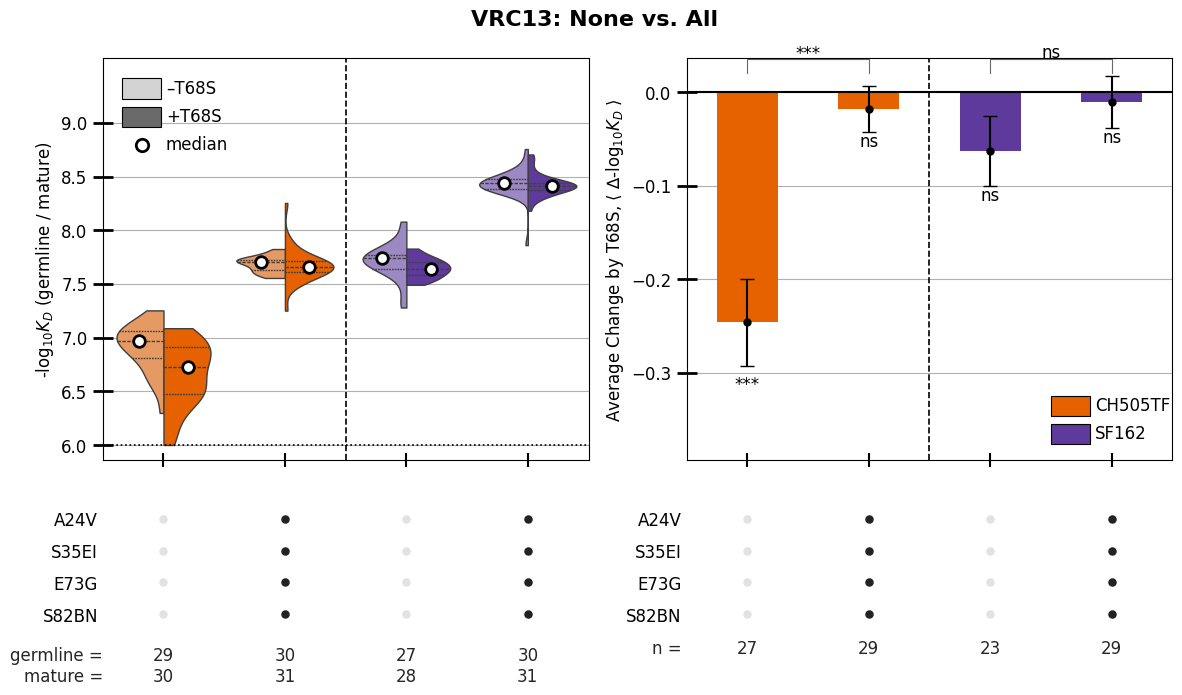

In [ ]:
none_all(bnab = 'VRC13',
             df_function = token_kds,
             background = [5],
             panels = [1,3,7,9],
             panels_identity = 'M',
             plot_tobit= False,
             plot_raw_avg = False,
             save_fig = True,
             save_fig_title = 'compressed_nolines',
             save_fig_format = '.pdf')


[list(['89', '85', '115', '106', '117', '112', '73', '114'])
 list(['92', '103', '116', '105', '118', '114', '101', '114'])]


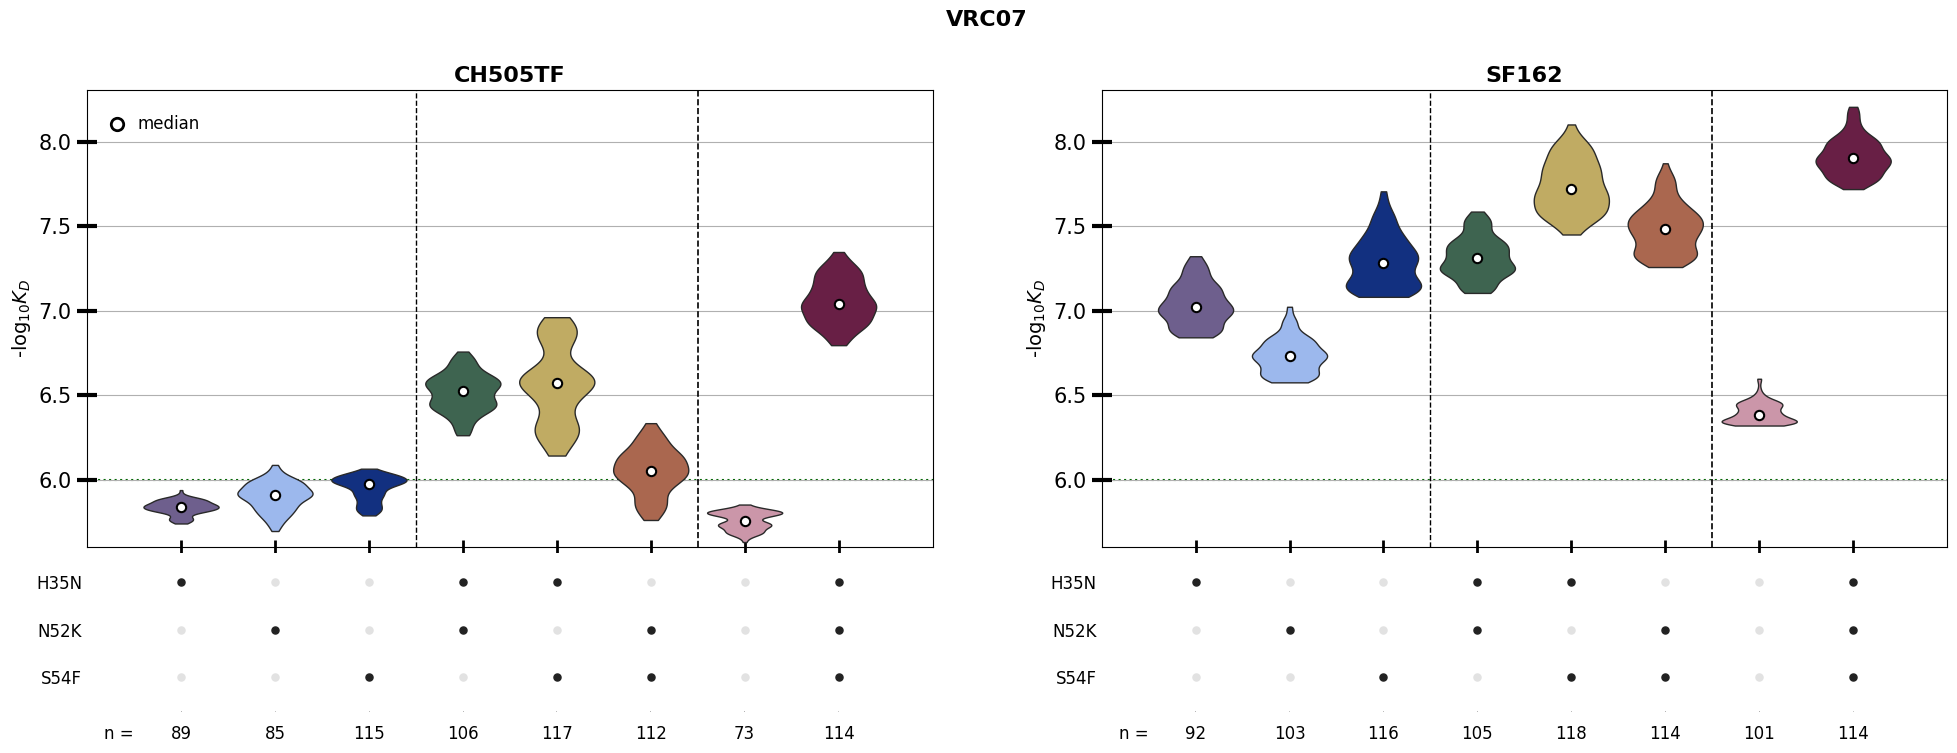

In [ ]:
plot_graph('VRC07', token_tobit_updated,  [], [2,5,6],plot_split = False, combinatorial_function = combinatorial_new,
           save_fig = True, save_fig_mode = '.pdf', tobit_col = 'uncensor', save_fig_title = 'supp:tobit_uncensored_VRC07',color_l = global_my_colors_none_first
           )